# NicheJEPA Benchmarking

- Creator: Sebastian Birk (sb75@sanger.ac.uk)
- Date of Creation: 26.01.2025
- Date of Last Modification: 25.12.2025 (by Sebastian Birk; sb75@sanger.ac.uk)

- Run this notebook in the nichejepa-reproducibility conda environment ```../../envs/nichejepa-reproducibility.yaml``` or the rapids_singlecell_nichejepa conda environment ```../../envs/rsc_rapids_25.10_nichejepa.yaml``` (GPU-accelerated clustering).

## 1. Setup

### 1.1 Load Libraries 

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../../utils")

In [3]:
import logging
import os
import warnings

import anndata as ad
try:
    import squidpy as sq
    print("Did not load rapids singlecell...")
except:
    import dask
    dask.config.set({"dataframe.query-planning": True}) # this is required to make rapids_singlecell work
    import dask.dataframe.dask_expr
    import rapids_singlecell as rsc
    print("Did not load squidpy...")
import pandas as pd
import scanpy as sc
import scib_metrics
from app.infer import harmonize_tokenize_embed_pipeline
from sklearn.metrics.cluster import adjusted_rand_score, normalized_mutual_info_score

from analysis_utils import *
from benchmarking_utils import max_overlap_plot

/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


Did not load rapids singlecell...


/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 1.2 Configure Paths

In [5]:
st_data_folder_path = '/lustre/scratch126/cellgen/lotfollahi/DATASETS'
st_data_silver_folder_path = f'{st_data_folder_path}/silver'
artifacts_folder_path = '/nfs/team361/sb75/nichejepa-reproducibility/artifacts'
benchmarking_artifacts_folder_path = f'{artifacts_folder_path}/benchmarking'
#model_timestamp = '01112025_081731_614'
model_timestamp = '16012026_015702_335'
model_folder_path = f'/nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/{model_timestamp}'
cache_directory_path = f'/nfs/team361/sb75/nichejepa-reproducibility/artifacts/cache'

### 1.3 Define Config

In [6]:
min_cells_per_gene = 0
min_cells_per_niche = 100
latent_neighborhood_cluster_key = 'predicted_niche'
latent_cell_cluster_key = 'predicted_cell_type'

### 1.4 Run Notebook Setup

In [7]:
warnings.filterwarnings("ignore", category=ResourceWarning)

In [8]:
plt.rcParams['font.size'] = 5
plt.rcParams['text.usetex'] = False
plt.rcParams['svg.fonttype'] = 'none'

In [9]:
# Improve reproducibility of UMAP and Leiden
os.environ['NUMBA_CPU_NAME'] = 'generic'

In [10]:
sc.settings.figdir = f'{benchmarking_artifacts_folder_path}/figures'

sc.settings.set_figure_params(
    dpi=300,
    dpi_save=300,
    figsize=(3, 2),
    facecolor='white',
    fontsize=7
)

In [11]:
os.makedirs(f'{benchmarking_artifacts_folder_path}/figures', exist_ok=True)
os.makedirs(f'{benchmarking_artifacts_folder_path}/results', exist_ok=True)
os.makedirs(f'{benchmarking_artifacts_folder_path}/NicheJEPA', exist_ok=True)

## 2. Zero-shot Niche Identification

### 2.1 chl59-8b_1p (NanoString CosMx Human NSCLC)

#### 2.1.1 Load Data

In [42]:
# Define dataset params
dataset_name = 'chl59-8b_1p'
batches = ['Lung9_Rep1',
           'Lung9_Rep2',
           'Lung5_Rep1',
           'Lung5_Rep2',
           'Lung6',
           'Lung12']
niche_key = 'niche'
batch_key = 'batch'
spot_sizes = [80 * 0.18] * len(batches)

In [43]:
# Load adata batches and concatenate for inference
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)

            # Filter cells without niche labels
            adata = adata[~adata.obs[niche_key].isna()]

            adata.obs['batch'] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)
adata.obsm['spatial'] = adata.obsm['spatial'] * 0.18 # conversion rate from https://nanostring-public-share.s3.us-west-2.amazonaws.com/SMI-Compressed/SMI-ReadMe.html

/tmp/ipykernel_1219096/2347038608.py:13: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs['batch'] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
/tmp/ipykernel_1219096/2347038608.py:13: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs['batch'] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
/tmp/ipykernel_1219096/2347038608.py:13: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs['batch'] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
/tmp/ipykernel_1219096/2347038608.py:13: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs['batch'] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
/tmp/ipykernel_1219096/2347038608.py:13: ImplicitMod

#### 2.1.2 Retrieve Embeddings

In [44]:
# Generate zero-shot embeddings for cells
adata = harmonize_tokenize_embed_pipeline(
    adata=adata,
    sample_key=batch_key,
    model_folder_path=model_folder_path,
    cache_directory_path=cache_directory_path,
    min_cells_per_gene=min_cells_per_gene,
    batch_size=128)

Start processing sample: 59batch4...
Harmonizing sample 59batch4...
STEP 1: DATA VALIDATION...
Checking that adata.X contains raw counts...
STEP 2: ADDING ENSEMBL IDS...
Adding ensembl IDs from gene_mapping_dict with file path `/lustre/scratch126/cellgen/lotfollahi/DATASETS/genes/homo_sapiens_gene_name_to_ensembl_id_dict.pkl`...
Number of genes with matching ensembl IDs: 946.
Number of genes skipped due to non-matching ensembl IDs: 0.
Filtering genes that have not occurred enough during pretraining...
Number of genes skipped due to not enough pretraining occurrences: 0.


/nfs/team361/sb75/nichejepa/src/app/infer.py:771: ImplicitModificationWarning: Trying to modify index of attribute `.var` of view, initializing view as actual.
  adata.var.index = adata_gene_names


STEP 3: BASIC QUALITY CONTROL...
Filtering cells with less than 10 genes.
Filtering genes expressed in less than 0 cells.


INFO:nichejepa.tokenizers.cell_tokenizers:Loading token dictionary from /nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/16012026_015702_335/token_dictionary.pkl.


STEP 4: ADDING SPECIAL VALUES...
Harmonized sample 59batch4.
Tokenizing sample 59batch4...
STEP 1: LOADING CONFIG...
STEP 2: TOKENIZING ANNDATA OBJECT...
Filtering cells...
No 'filter_pass' column in 'adata.obs'; returning full adata.
Computing spatial neighborhood...
Normalizing gene expression counts...
Retrieving gene tokens.
Ranking gene tokens based on normalized counts.


/nfs/team361/sb75/nichejepa/src/nichejepa/tokenizers/cell_tokenizers.py:663: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  coding_miRNA_ids = adata.var['ensembl_id'][coding_miRNA_idx]


... (40 outputs left out)

Tokenized sample 59batch0.
Concatenating tokenized data...
Concatenated tokenized data.
Embedding tokenized data...
STEP 1: LOADING CONFIG...
STEP 2: GENERATING EMBEDDINGS...


INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (seg_embed): Embedding(13, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affi

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr']


0it [00:00, ?it/s]/nfs/team361/sb75/nichejepa/src/app/infer.py:1118: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
2167it [1:12:52,  2.01s/it]Process Process-15:
Process Process-19:
Process Process-18:
Process Process-17:
Process Process-20:
Process Process-13:
Process Process-16:
Process Process-14:
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
  File "/software/cellgen/team361/sb75/envs/nichejepa/lib/python3.10/multiprocessing/process.py", line 317, in _bootstrap
    util._exit_function()
  File "/software/cellgen/team361/sb75/envs/nichejepa/lib/python3.10/multiprocessing/process.py", line 317, in _bootstrap
    util._exit_function()
  File "/software/cellgen/team361/sb75/envs/nich

In [ ]:
# Compute neighbors and UMAP 
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep=f'neighborhood_emb',
                key_added='neighborhood')
sc.tl.umap(adata,
           neighbors_key='neighborhood')

In [ ]:
# Visualize UMAP
sc.pl.umap(adata, color=niche_key)

In [ ]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/NicheJEPA/{dataset_name}_embedded_{model_timestamp}.h5ad')

In [ ]:
# Read AnnData
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/NicheJEPA/{dataset_name}_embedded_{model_timestamp}.h5ad')

#### 2.1.3 Highlight Run (Matching Ground Truth Number of Niches)

In [ ]:
# Compute Leiden clustering (matching the number of clusters with the ground truth with > 100 cells -> 12)
latent_leiden_resolution = 0.32

sc.tl.leiden(adata,
             neighbors_key='neighborhood',
             key_added=latent_neighborhood_cluster_key,
             resolution=latent_leiden_resolution)

In [ ]:
adata.obs[latent_neighborhood_cluster_key].value_counts()

In [ ]:
# Visualize UMAP
sc.pl.umap(adata, color=latent_neighborhood_cluster_key)

In [ ]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/NicheJEPA/{dataset_name}_embedded_clustered_{model_timestamp}.h5ad')

In [ ]:
# Read AnnData
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/NicheJEPA/{dataset_name}_embedded_clustered_{model_timestamp}.h5ad')

In [ ]:
print(adata.obs[latent_neighborhood_cluster_key].unique().tolist())
print(adata.obs[latent_neighborhood_cluster_key].value_counts())
max_overlap_plot(adata.obs, niche_key, latent_neighborhood_cluster_key)

In [ ]:
inferred_niches_ordered = [
    '8',
    '1',
    '2',
    '7',
    '10',
    '6',
    '4',
    '5',
    '11',
    '3',
    '9',
    '0']

In [ ]:
# Plot NicheJEPA niches
label2niche = {}
current_index = 0  # To keep track of the new indices

for niche in inferred_niches_ordered:
    if not isinstance(niche, str):
        if math.isnan(niche):
            continue # skip NaN values
    label2niche[str(current_index)] = niche
    current_index += 1

pred_palette = {
    label2niche.get(k, k): v
    for k, v in custom_palette.items()
}

batch_ids = adata.obs[batch_key].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs[batch_key] == batch_id]
    file_name = f'{dataset_name}_{batch_id}_nichejepa_niches_{model_timestamp}.svg'
    sc.pl.spatial(adata_batch,
                  color=latent_neighborhood_cluster_key,
                  palette=pred_palette,
                  spot_size=spot_sizes[i],
                  save=file_name)

In [ ]:
# Compute metrics
labels = adata.obs[niche_key]
labels_pred = adata.obs[latent_neighborhood_cluster_key]
labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])

nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
ari_score = adjusted_rand_score(labels, labels_pred)

print(f"NMI scores: {nmi_score}.")
print(f"ARI scores: {ari_score}.")

#### 2.1.4 Quantitative Performance

In [ ]:
# Compute metrics over different resolutions
nmi_scores = []
ari_scores = []
n_niches_list = []

nmi_scores.append(nmi_score)
ari_scores.append(ari_score)
n_niches_list.append(adata.obs[latent_neighborhood_cluster_key].nunique())

latent_leiden_resolution_list = [latent_leiden_resolution,
                                 latent_leiden_resolution-0.04,
                                 latent_leiden_resolution-0.03,
                                 latent_leiden_resolution-0.02,
                                 latent_leiden_resolution-0.01,
                                 latent_leiden_resolution+0.01,
                                 latent_leiden_resolution+0.02,
                                 latent_leiden_resolution+0.03,
                                 latent_leiden_resolution+0.04]

for i, latent_leiden_resolution in enumerate(latent_leiden_resolution_list[1:]):

    sc.tl.leiden(adata,
                 neighbors_key='neighborhood',
                 key_added=latent_neighborhood_cluster_key,
                 resolution=latent_leiden_resolution)

    n_niches_list.append(adata.obs[latent_neighborhood_cluster_key].nunique())
    
    labels = adata.obs[niche_key]
    labels_pred = adata.obs[latent_neighborhood_cluster_key]
    labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])
    
    nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
    ari_score = adjusted_rand_score(labels, labels_pred)

    nmi_scores.append(nmi_score)
    ari_scores.append(ari_score)

    # Store on disk
    metrics_df = pd.DataFrame({
        'leiden_resolution': latent_leiden_resolution_list[:i+2],
        'n_niches': n_niches_list,
        'NMI': nmi_scores,
        'ARI': ari_scores
    })
    metrics_df.to_csv(f'{benchmarking_artifacts_folder_path}/results/{dataset_name}_nichejepa_metric_scores_{model_timestamp}.csv', index=False)

print(f"NMI scores: {nmi_scores}.")
print(f"ARI scores: {ari_scores}.")

### 2.2 chr78-11b_1p (ISS Cartana Human Reproductive Tract)

In [ ]:
# Define dataset params
dataset_name = 'chr78-11b_1p'
batches = ['CM007',
           'CM008',
           'CM009',
           'CM011',
           'CM013',
           'CM015',
           'CM016',
           'CM017',
           'CM018',
           'CM019',
           'CM020']
niche_key = 'broad_anatomy'
batch_key = 'batch'
spot_sizes = [240 * 0.093] * len(batches)

#### 2.2.1 Load Data

In [ ]:
# Load adata batches and concatenate for inference
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)
            adata.obs['batch'] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)
adata.obsm['spatial'] = adata.obsm['spatial'] * 0.093 # conversion rate from Valentina

In [ ]:
# Combine regions
adata.obs[niche_key] = adata.obs[niche_key].apply(lambda x: x.replace('Urogenital Sinus', 'UrogenitalSinus'))

In [ ]:
print(adata.obs[niche_key].value_counts())

#### 2.2.2 Retrieve Embeddings

In [ ]:
# Generate zero-shot embeddings for cells
adata = harmonize_tokenize_embed_pipeline(
    adata=adata,
    sample_key=batch_key,
    model_folder_path=model_folder_path,
    cache_directory_path=cache_directory_path,
    min_cells_per_gene=min_cells_per_gene,
    batch_size=128)

In [ ]:
# Compute neighbors and UMAP 
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep=f'neighborhood_emb',
                key_added='neighborhood')
sc.tl.umap(adata,
           neighbors_key='neighborhood')

In [ ]:
# Visualize UMAP
sc.pl.umap(adata, color=niche_key)

In [ ]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/NicheJEPA/{dataset_name}_embedded_{model_timestamp}.h5ad')

In [ ]:
# Read AnnData
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/NicheJEPA/{dataset_name}_embedded_{model_timestamp}.h5ad')

#### 2.2.3 Highlight Run (Matching Ground Truth Number of Niches)

In [ ]:
# Compute Leiden clustering (matching the number of clusters with the ground truth with > 100 cells -> 19)
latent_leiden_resolution = 0.3

sc.tl.leiden(adata,
             neighbors_key='neighborhood',
             key_added=latent_neighborhood_cluster_key,
             resolution=latent_leiden_resolution)

In [ ]:
adata.obs[latent_neighborhood_cluster_key].value_counts()

In [ ]:
# Visualize UMAP
sc.pl.umap(adata, color=latent_neighborhood_cluster_key)

In [ ]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/NicheJEPA/{dataset_name}_embedded_clustered_{model_timestamp}.h5ad')

In [ ]:
# Read AnnData
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/NicheJEPA/{dataset_name}_embedded_clustered_{model_timestamp}.h5ad')

In [ ]:
print(adata.obs[latent_neighborhood_cluster_key].unique().tolist())
print(adata.obs[latent_neighborhood_cluster_key].value_counts())
max_overlap_plot(adata.obs, niche_key, latent_neighborhood_cluster_key)

In [ ]:
inferred_niches_ordered = [
    '15',
    '6',
    '11',
    '4',
    '7',
    '1',
    '3',
    '5',
    '16',
    '8',
    '10',
    '13',
    '18',
    '17',
    '9',
    '14',
    '12',
    '2',
    '0',
    '19']

In [ ]:
# Plot NicheJEPA niches
label2niche = {}
current_index = 0  # To keep track of the new indices

for niche in inferred_niches_ordered:
    if not isinstance(niche, str):
        if math.isnan(niche):
            continue # skip NaN values
    label2niche[str(current_index)] = niche
    current_index += 1

pred_palette = {
    label2niche.get(k, k): v
    for k, v in custom_palette.items()
}

batch_ids = adata.obs[batch_key].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs[batch_key] == batch_id]
    file_name = f'{dataset_name}_{batch_id}_nichejepa_niches_{model_timestamp}.svg'
    sc.pl.spatial(adata_batch,
                  color=latent_neighborhood_cluster_key,
                  palette=pred_palette,
                  spot_size=spot_sizes[i],
                  save=file_name)

In [ ]:
# Compute metrics
labels = adata.obs[niche_key]
labels_pred = adata.obs[latent_neighborhood_cluster_key]
labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])

nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
ari_score = adjusted_rand_score(labels, labels_pred)

print(f"NMI scores: {nmi_score}.")
print(f"ARI scores: {ari_score}.")

#### 2.2.4 Quantitative Performance

In [ ]:
# Compute metrics over different resolutions
nmi_scores = []
ari_scores = []
n_niches_list = []

nmi_scores.append(nmi_score)
ari_scores.append(ari_score)
n_niches_list.append(adata.obs[latent_neighborhood_cluster_key].nunique())

latent_leiden_resolution_list = [latent_leiden_resolution,
                                 latent_leiden_resolution-0.04,
                                 latent_leiden_resolution-0.03,
                                 latent_leiden_resolution-0.02,
                                 latent_leiden_resolution-0.01,
                                 latent_leiden_resolution+0.01,
                                 latent_leiden_resolution+0.02,
                                 latent_leiden_resolution+0.03,
                                 latent_leiden_resolution+0.04]

for i, latent_leiden_resolution in enumerate(latent_leiden_resolution_list[1:]):

    sc.tl.leiden(adata,
                 neighbors_key='neighborhood',
                 key_added=latent_neighborhood_cluster_key,
                 resolution=latent_leiden_resolution)

    n_niches_list.append(adata.obs[latent_neighborhood_cluster_key].nunique())
    
    labels = adata.obs[niche_key]
    labels_pred = adata.obs[latent_neighborhood_cluster_key]
    labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])
    
    nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
    ari_score = adjusted_rand_score(labels, labels_pred)

    nmi_scores.append(nmi_score)
    ari_scores.append(ari_score)

    # Store on disk
    metrics_df = pd.DataFrame({
        'leiden_resolution': latent_leiden_resolution_list[:i+2],
        'n_niches': n_niches_list,
        'NMI': nmi_scores,
        'ARI': ari_scores
    })
    metrics_df.to_csv(f'{benchmarking_artifacts_folder_path}/results/{dataset_name}_nichejepa_metric_scores_{model_timestamp}.csv', index=False)

print(f"NMI scores: {nmi_scores}.")
print(f"ARI scores: {ari_scores}.")

### 2.3 xhs49-1b_1p (Xenium Human Melanoma)

In [ ]:
dataset_name = 'xhs49-1b_1p'
niche_key = 'niche_name'
spot_size = 20

#### 2.3.1 Load Data

In [ ]:
adata = sc.read_h5ad(f'{st_data_silver_folder_path}/{dataset_name}/Xenium_Prime_Human_Skin_FFPE_outs.h5ad')

# Filter cells without niche labels
adata = adata[~adata.obs['niche_name'].isna()]

In [ ]:
adata.obs[niche_key].value_counts()

#### 2.3.2 Retrieve Embeddings

In [ ]:
# Generate zero-shot embeddings for cells
adata = harmonize_tokenize_embed_pipeline(
    adata=adata,
    sample_key=None,
    model_folder_path=model_folder_path,
    cache_directory_path=cache_directory_path,
    min_cells_per_gene=min_cells_per_gene,
    batch_size=128)

In [ ]:
# Compute neighbors and UMAP 
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep=f'neighborhood_emb',
                key_added='neighborhood')
sc.tl.umap(adata,
           neighbors_key='neighborhood')

In [ ]:
# Visualize UMAP
sc.pl.umap(adata, color=niche_key)

In [ ]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/NicheJEPA/{dataset_name}_embedded_{model_timestamp}.h5ad')

In [ ]:
# Read AnnData
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/NicheJEPA/{dataset_name}_embedded_{model_timestamp}.h5ad')

#### 2.3.3 Highlight Run (Matching Ground Truth Number of Niches)

In [ ]:
# Compute Leiden clustering (matching the number of clusters with the ground truth with > 100 cells -> 8)
latent_leiden_resolution = 0.5

sc.tl.leiden(adata,
             neighbors_key='neighborhood',
             key_added=latent_neighborhood_cluster_key,
             resolution=latent_leiden_resolution)

In [ ]:
adata.obs[latent_neighborhood_cluster_key].value_counts()

In [ ]:
# Visualize UMAP
sc.pl.umap(adata, color=latent_neighborhood_cluster_key)

In [ ]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/NicheJEPA/{dataset_name}_embedded_clustered_{model_timestamp}.h5ad')

In [ ]:
# Read AnnData
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/NicheJEPA/{dataset_name}_embedded_clustered_{model_timestamp}.h5ad')

In [ ]:
print(adata.obs[latent_neighborhood_cluster_key].unique().tolist())
print(adata.obs[latent_neighborhood_cluster_key].value_counts())
max_overlap_plot(adata.obs, niche_key, latent_neighborhood_cluster_key)

In [ ]:
inferred_niches_ordered = [
    '5',
    '4',
    '2',
    '6',
    '0',
    '7',
    '1',
    '3']

In [ ]:
# Plot NicheJEPA niches
label2niche = {}
current_index = 0  # To keep track of the new indices

for niche in inferred_niches_ordered:
    if not isinstance(niche, str):
        if math.isnan(niche):
            continue # skip NaN values
    label2niche[str(current_index)] = niche
    current_index += 1

pred_palette = {
    label2niche.get(k, k): v
    for k, v in custom_palette.items()
}

file_name = f'{dataset_name}_nichejepa_niches_{model_timestamp}.svg'
sc.pl.spatial(adata,
              color=latent_neighborhood_cluster_key,
              palette=pred_palette,
              spot_size=spot_size,
              save=file_name)

In [ ]:
# Compute metrics
labels = adata.obs[niche_key]
labels_pred = adata.obs[latent_neighborhood_cluster_key]
labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])

nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
ari_score = adjusted_rand_score(labels, labels_pred)

print(f"NMI scores: {nmi_score}.")
print(f"ARI scores: {ari_score}.")

#### 2.3.4 Quantitative Performance

In [ ]:
# Compute metrics over different resolutions
nmi_scores = []
ari_scores = []
n_niches_list = []

nmi_scores.append(nmi_score)
ari_scores.append(ari_score)
n_niches_list.append(adata.obs[latent_neighborhood_cluster_key].nunique())

latent_leiden_resolution_list = [latent_leiden_resolution,
                                 latent_leiden_resolution-0.04,
                                 latent_leiden_resolution-0.03,
                                 latent_leiden_resolution-0.02,
                                 latent_leiden_resolution-0.01,
                                 latent_leiden_resolution+0.01,
                                 latent_leiden_resolution+0.02,
                                 latent_leiden_resolution+0.03,
                                 latent_leiden_resolution+0.04]

for i, latent_leiden_resolution in enumerate(latent_leiden_resolution_list[1:]):

    sc.tl.leiden(adata,
                 neighbors_key='neighborhood',
                 key_added=latent_neighborhood_cluster_key,
                 resolution=latent_leiden_resolution)

    n_niches_list.append(adata.obs[latent_neighborhood_cluster_key].nunique())
    
    labels = adata.obs[niche_key]
    labels_pred = adata.obs[latent_neighborhood_cluster_key]
    labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])
    
    nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
    ari_score = adjusted_rand_score(labels, labels_pred)

    nmi_scores.append(nmi_score)
    ari_scores.append(ari_score)

    # Store on disk
    metrics_df = pd.DataFrame({
        'leiden_resolution': latent_leiden_resolution_list[:i+2],
        'n_niches': n_niches_list,
        'NMI': nmi_scores,
        'ARI': ari_scores
    })
    metrics_df.to_csv(f'{benchmarking_artifacts_folder_path}/results/{dataset_name}_nichejepa_metric_scores_{model_timestamp}.csv', index=False)

print(f"NMI scores: {nmi_scores}.")
print(f"ARI scores: {ari_scores}.")

### 2.4 xhs1000-39b_1p (Xenium Human Skin - Eczema)

#### 2.4.1 Load Data

In [15]:
# Define dataset params
dataset_name = 'xhs1000-39b_1p'
batches = ['batch11',
           'batch19',
           'batch32']
niche_key = 'niche_type'
batch_key = 'sample'
spot_sizes = [20] * len(batches)

In [16]:
# Load adata batches and concatenate for inference
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)

            # Filter cells without niche labels
            adata = adata[~adata.obs[niche_key].isna()]

            adata.obs['batch'] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)
adata.obsm['spatial'] = adata.obsm['spatial']

/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/tmp/ipykernel_1219096/205002708.py:13: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs['batch'] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/tmp/ipykernel_1219096/205002708.py:13: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs['batch'] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
/tmp/ipykernel_1219096/205002708.py:13: ImplicitModificati

#### 2.4.2 Retrieve Embeddings

In [17]:
# Generate zero-shot embeddings for cells
adata = harmonize_tokenize_embed_pipeline(
    adata=adata,
    sample_key='batch',
    model_folder_path=model_folder_path,
    cache_directory_path=cache_directory_path,
    min_cells_per_gene=min_cells_per_gene,
    batch_size=128)

Start processing sample: 1000batch32...
Harmonizing sample 1000batch32...
STEP 1: DATA VALIDATION...
Checking that adata.X contains raw counts...
STEP 2: ADDING ENSEMBL IDS...
Adding ensembl IDs from gene_mapping_dict with file path `/lustre/scratch126/cellgen/lotfollahi/DATASETS/genes/homo_sapiens_gene_name_to_ensembl_id_dict.pkl`...


/nfs/team361/sb75/nichejepa/src/app/infer.py:771: ImplicitModificationWarning: Trying to modify index of attribute `.var` of view, initializing view as actual.
  adata.var.index = adata_gene_names


Number of genes with matching ensembl IDs: 4948.
Number of genes skipped due to non-matching ensembl IDs: 0.
Filtering genes that have not occurred enough during pretraining...
Number of genes skipped due to not enough pretraining occurrences: 0.
STEP 3: BASIC QUALITY CONTROL...
Filtering cells with less than 10 genes.
Filtering genes expressed in less than 0 cells.


INFO:nichejepa.tokenizers.cell_tokenizers:Loading token dictionary from /nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/16012026_015702_335/token_dictionary.pkl.


STEP 4: ADDING SPECIAL VALUES...
Harmonized sample 1000batch32.
Tokenizing sample 1000batch32...
STEP 1: LOADING CONFIG...
STEP 2: TOKENIZING ANNDATA OBJECT...
Filtering cells...
No 'filter_pass' column in 'adata.obs'; returning full adata.
Computing spatial neighborhood...
Normalizing gene expression counts...
Retrieving gene tokens.
Ranking gene tokens based on normalized counts.


/nfs/team361/sb75/nichejepa/src/nichejepa/tokenizers/cell_tokenizers.py:663: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  coding_miRNA_ids = adata.var['ensembl_id'][coding_miRNA_idx]


... (19 outputs left out)

INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (seg_embed): Embedding(13, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affi

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr']


0it [00:00, ?it/s]/nfs/team361/sb75/nichejepa/src/app/infer.py:1118: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
420it [14:08,  2.02s/it]
/nfs/team361/sb75/nichejepa/src/app/infer.py:1450: ImplicitModificationWarning: Setting element `.obsm['cell_emb']` of view, initializing view as actual.
  adata.obsm[key] = values


Embedded tokenized data.


In [18]:
# Compute neighbors and UMAP 
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep=f'neighborhood_emb',
                key_added='neighborhood')
sc.tl.umap(adata,
           neighbors_key='neighborhood')

... storing 'batch' as categorical


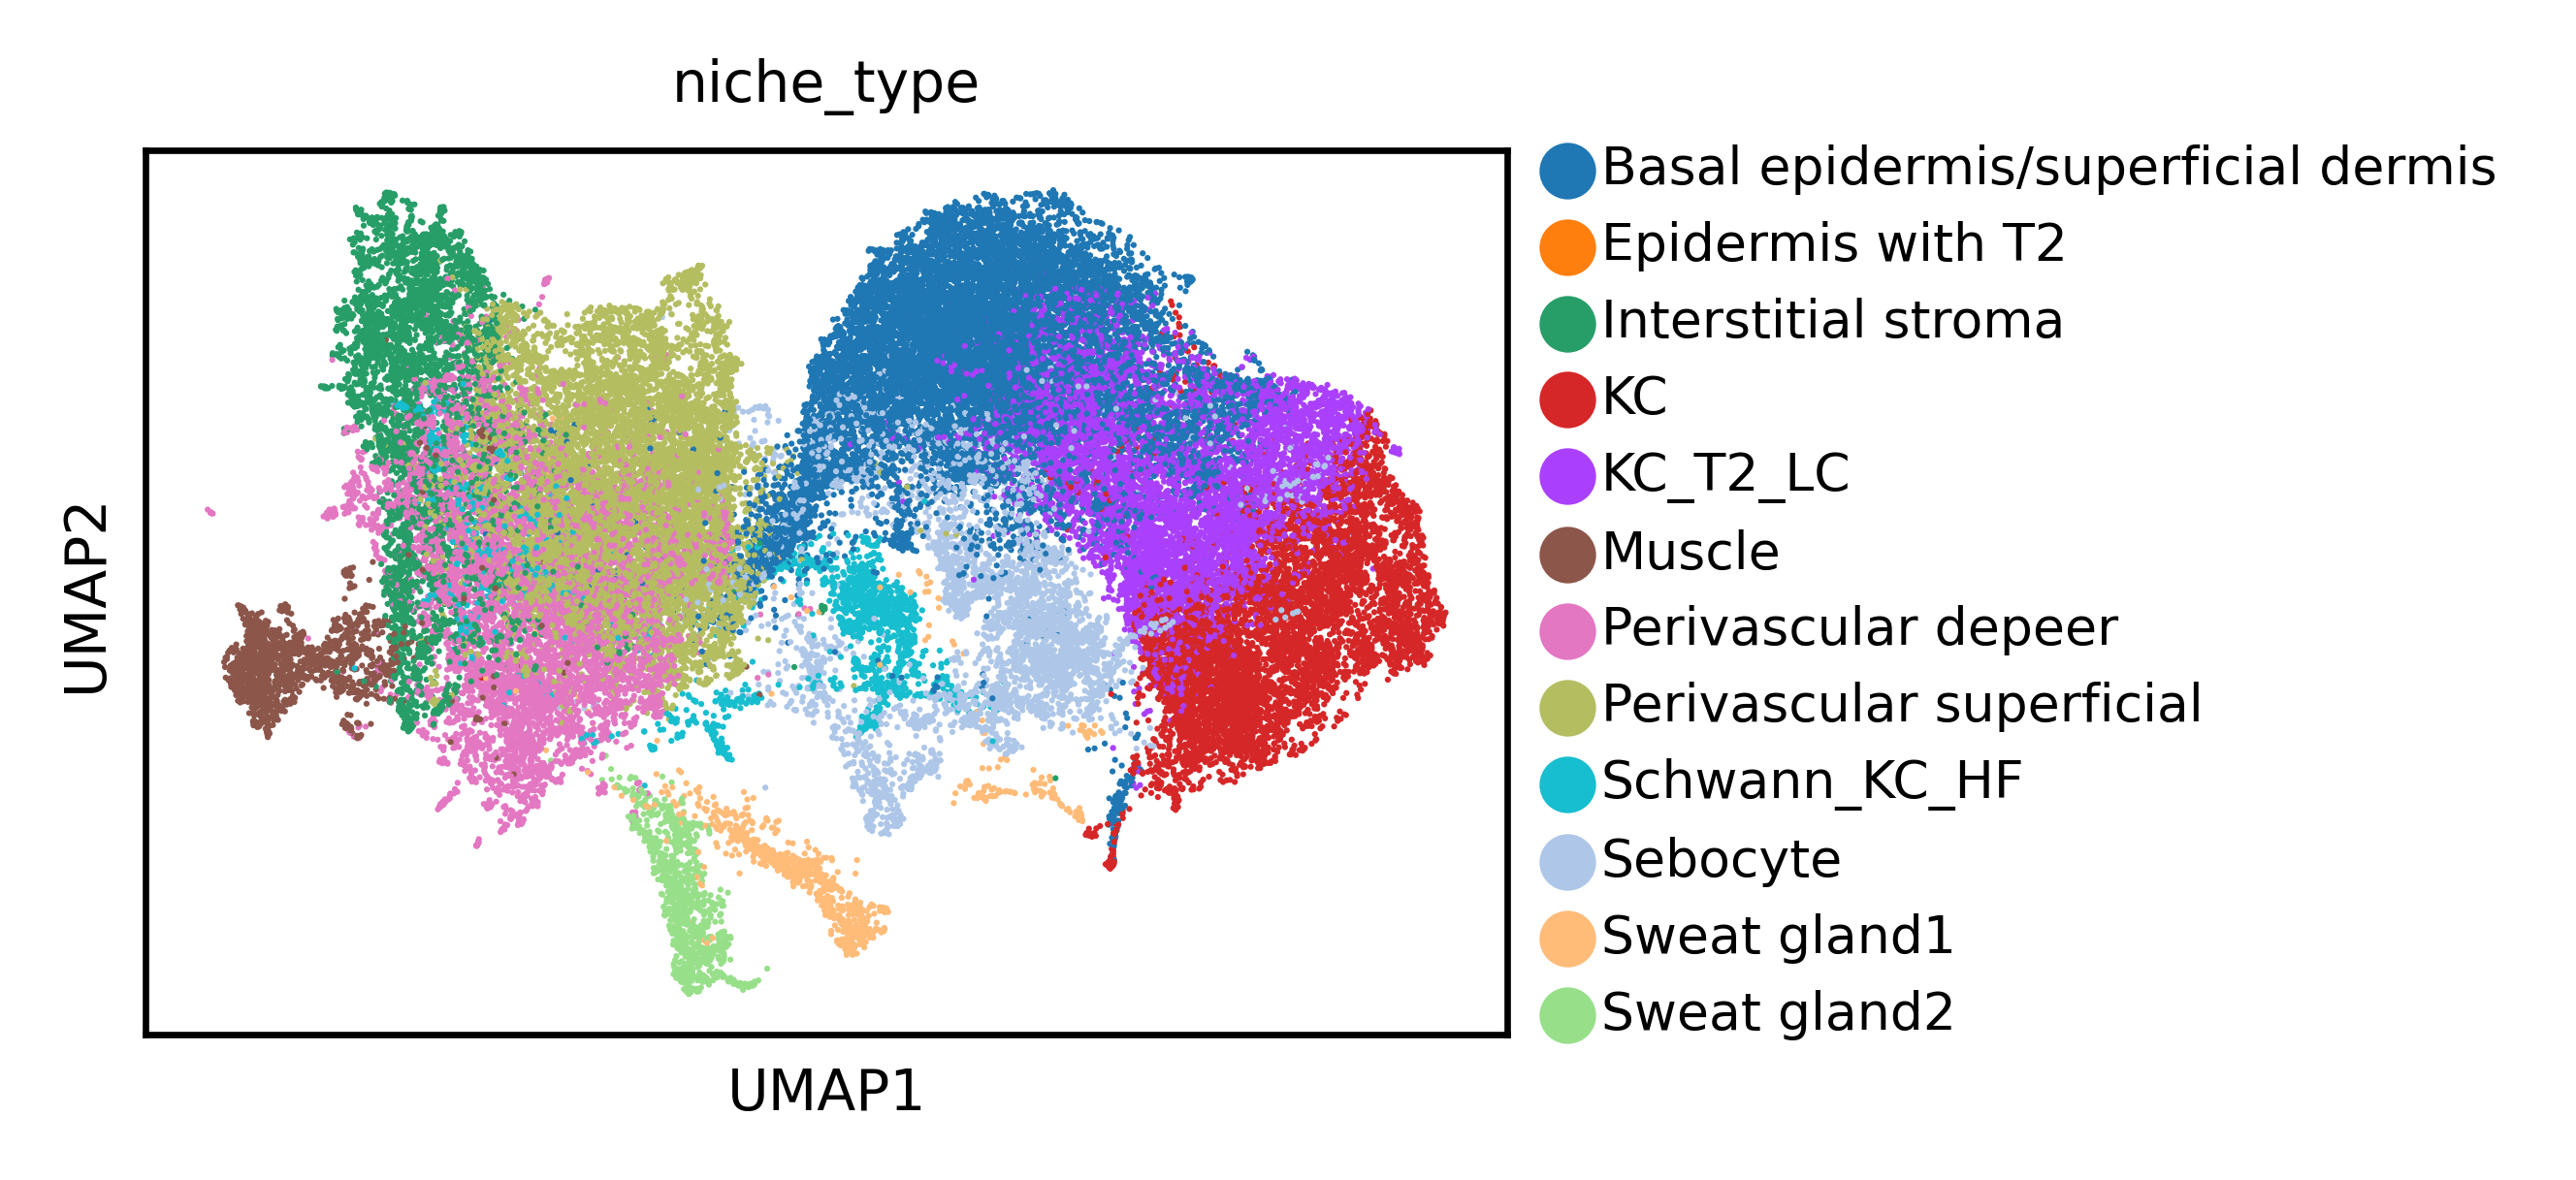

In [19]:
# Visualize UMAP
sc.pl.umap(adata, color=niche_key)

In [20]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/NicheJEPA/{dataset_name}_embedded_{model_timestamp}.h5ad')

In [ ]:
# Read AnnData
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/NicheJEPA/{dataset_name}_embedded_{model_timestamp}.h5ad')

#### 2.3.3 Highlight Run (Matching Ground Truth Number of Niches)

In [ ]:
# Compute Leiden clustering (matching the number of clusters with the ground truth with > 100 cells -> 11)
latent_leiden_resolution = 0.23

sc.tl.leiden(adata,
             neighbors_key='neighborhood',
             key_added=latent_neighborhood_cluster_key,
             resolution=latent_leiden_resolution)

In [ ]:
adata.obs[latent_neighborhood_cluster_key].value_counts()

In [ ]:
# Visualize UMAP
sc.pl.umap(adata, color=latent_neighborhood_cluster_key)

In [ ]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/NicheJEPA/{dataset_name}_embedded_clustered_{model_timestamp}.h5ad')

In [ ]:
# Read AnnData
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/NicheJEPA/{dataset_name}_embedded_clustered_{model_timestamp}.h5ad')

In [ ]:
print(adata.obs[latent_neighborhood_cluster_key].unique().tolist())
print(adata.obs[latent_neighborhood_cluster_key].value_counts())
max_overlap_plot(adata.obs, niche_key, latent_neighborhood_cluster_key)

In [ ]:
inferred_niches_ordered = [
    '1',
    '10',
    '5',
    '2',
    '9',
    '4',
    '11',
    '0',
    '7',
    '3',
    '8',
    '6']

In [ ]:
# Plot NicheJEPA niches
label2niche = {}
current_index = 0  # To keep track of the new indices

for niche in inferred_niches_ordered:
    if not isinstance(niche, str):
        if math.isnan(niche):
            continue # skip NaN values
    label2niche[str(current_index)] = niche
    current_index += 1

pred_palette = {
    label2niche.get(k, k): v
    for k, v in custom_palette.items()
}

batch_ids = adata.obs[batch_key].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs[batch_key] == batch_id]
    file_name = f'{dataset_name}_{batch_id}_nichejepa_niches_{model_timestamp}.svg'
    sc.pl.spatial(adata_batch,
                  color=latent_neighborhood_cluster_key,
                  palette=pred_palette,
                  spot_size=spot_sizes[i],
                  save=file_name)

In [ ]:
# Compute metrics
labels = adata.obs[niche_key]
labels_pred = adata.obs[latent_neighborhood_cluster_key]
labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])

nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
ari_score = adjusted_rand_score(labels, labels_pred)

print(f"NMI scores: {nmi_score}.")
print(f"ARI scores: {ari_score}.")

#### 2.3.4 Quantitative Performance

In [ ]:
# Compute metrics over different resolutions
nmi_scores = []
ari_scores = []
n_niches_list = []

nmi_scores.append(nmi_score)
ari_scores.append(ari_score)
n_niches_list.append(adata.obs[latent_neighborhood_cluster_key].nunique())

latent_leiden_resolution_list = [latent_leiden_resolution,
                                 latent_leiden_resolution-0.04,
                                 latent_leiden_resolution-0.03,
                                 latent_leiden_resolution-0.02,
                                 latent_leiden_resolution-0.01,
                                 latent_leiden_resolution+0.01,
                                 latent_leiden_resolution+0.02,
                                 latent_leiden_resolution+0.03,
                                 latent_leiden_resolution+0.04]

for i, latent_leiden_resolution in enumerate(latent_leiden_resolution_list[1:]):

    sc.tl.leiden(adata,
                 neighbors_key='neighborhood',
                 key_added=latent_neighborhood_cluster_key,
                 resolution=latent_leiden_resolution)

    n_niches_list.append(adata.obs[latent_neighborhood_cluster_key].nunique())
    
    labels = adata.obs[niche_key]
    labels_pred = adata.obs[latent_neighborhood_cluster_key]
    labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])
    
    nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
    ari_score = adjusted_rand_score(labels, labels_pred)

    nmi_scores.append(nmi_score)
    ari_scores.append(ari_score)

    # Store on disk
    metrics_df = pd.DataFrame({
        'leiden_resolution': latent_leiden_resolution_list[:i+2],
        'n_niches': n_niches_list,
        'NMI': nmi_scores,
        'ARI': ari_scores
    })
    metrics_df.to_csv(f'{benchmarking_artifacts_folder_path}/results/{dataset_name}_nichejepa_metric_scores_{model_timestamp}.csv', index=False)

print(f"NMI scores: {nmi_scores}.")
print(f"ARI scores: {ari_scores}.")

## 3. Zero-shot Cell Type Identification

### 3.1 xhs1000-39b_1p (Xenium Human Skin - Eczema)

#### 3.1.1 Load Data

In [21]:
# Define dataset params
dataset_name = 'xhs1000-39b_1p'
batches = ['batch11',
           'batch19',
           'batch32']
cell_type_key = 'new_annotation' # 'annotation_new7'
batch_key = 'sample'
spot_sizes = [20] * len(batches)

In [22]:
# Load adata batches and concatenate for inference
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)

            # Filter cells without cell type labels
            adata = adata[~adata.obs[cell_type_key].isna()]

            adata.obs[batch_key] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)

/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/tmp/ipykernel_1219096/3458664098.py:13: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[batch_key] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
/tmp/ipykernel_1219096/3458664098.py:13: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[batch_key] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
/tmp/ipykernel_1219096/3458664098.py:13: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[batch_key] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/pytho

In [23]:
print(adata.obs[cell_type_key].value_counts())

new_annotation
KC1                               9861
KC4                               8301
F2: Universal                     6307
KC3                               4896
T                                 4430
KCinflamm                         3020
Sebocyte_GATA6hi_innersebocyte    2948
VE3                               2692
cDC2                              2601
Pericyte                          1937
Mac                               1590
Muscle                            1241
KC_melanocyte                     1019
Sweat gland channel outer          651
Schwann                            642
Sweat gland                        587
LE                                 347
F5: RAMP1                          328
Mast cell                          200
Pre-adipocyte PPARG+ANGPTL8         52
Plasma cell                          5
Name: count, dtype: int64


#### 3.1.2 Load Embeddings

In [24]:
# Load embeddings from 2.4
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/NicheJEPA/{dataset_name}_embedded_{model_timestamp}.h5ad')

In [25]:
# Compute neighbors and UMAP 
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep=f'cell_emb',
                key_added='cell')
sc.tl.umap(adata,
           neighbors_key='cell')

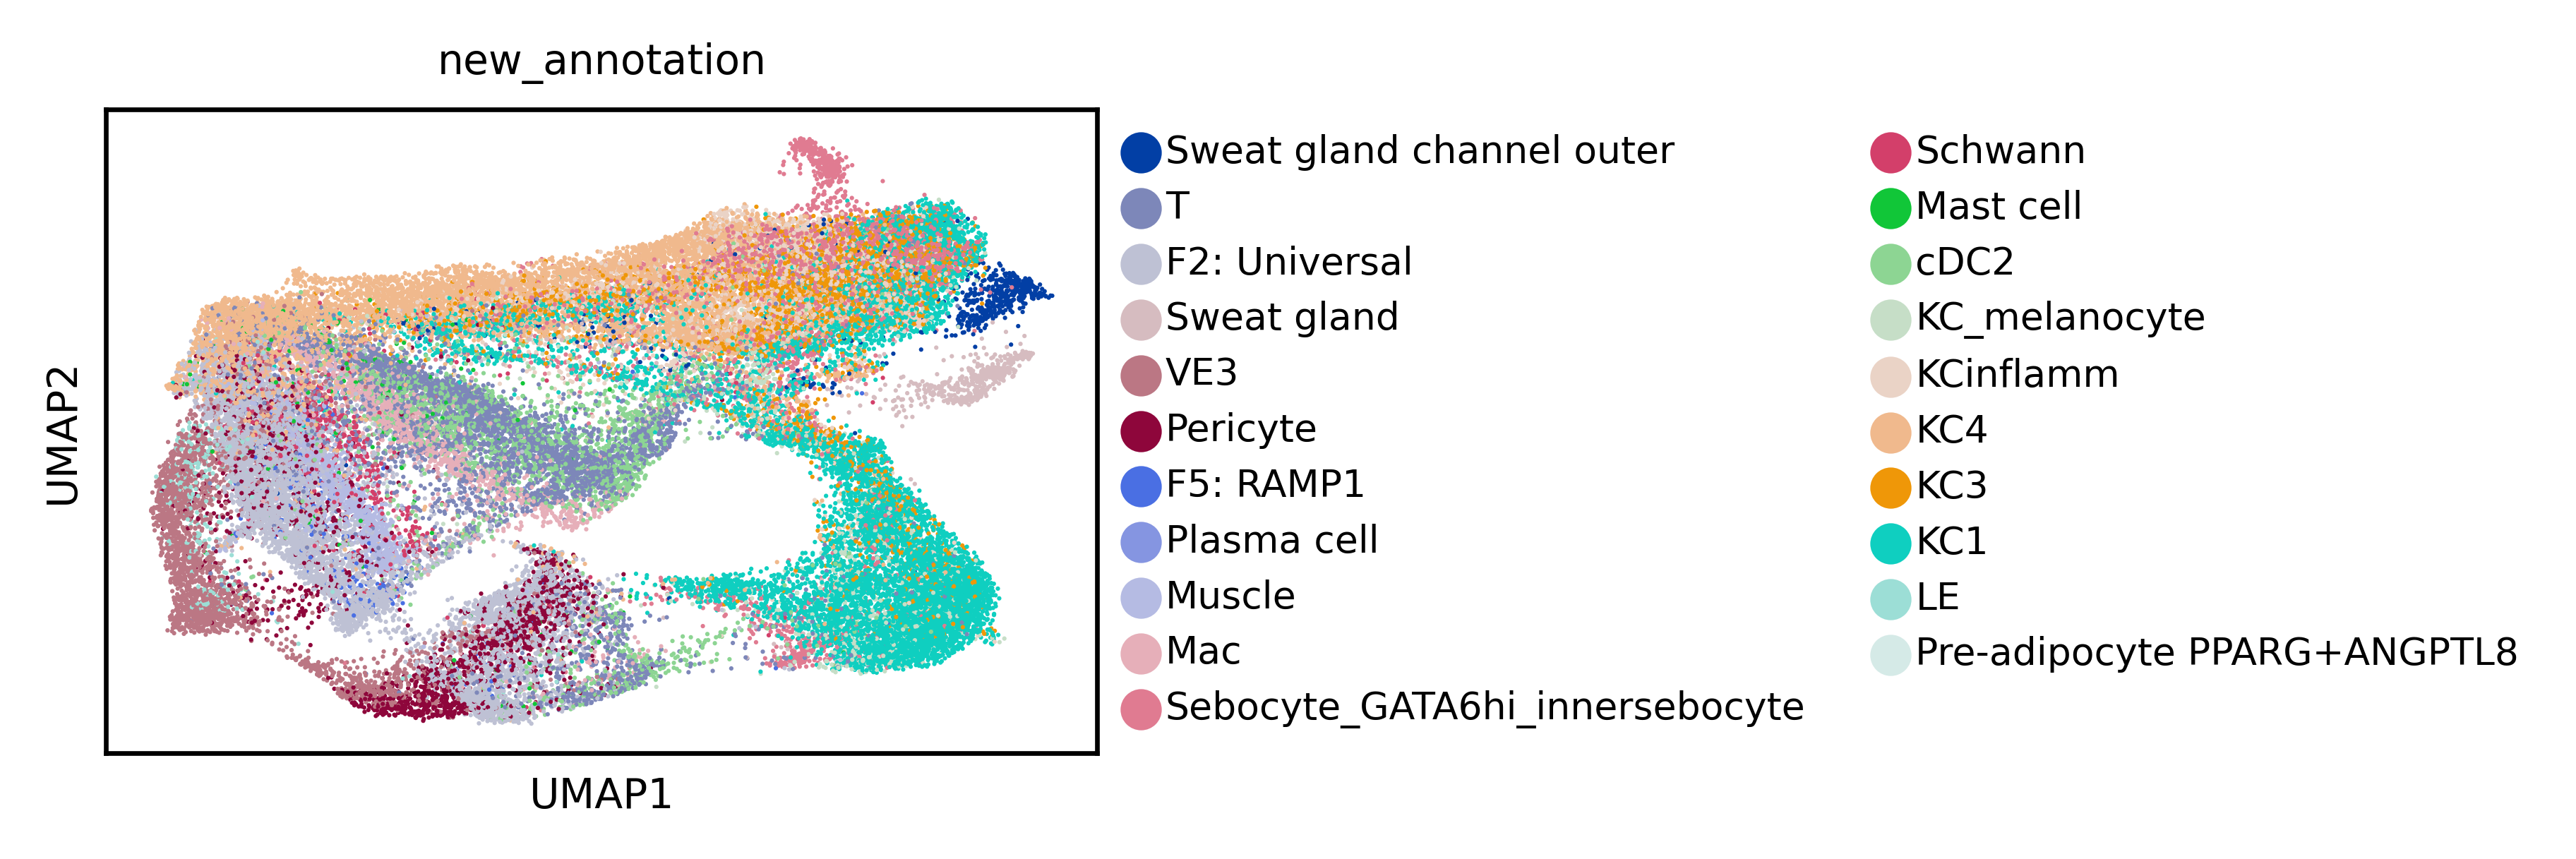

In [26]:
# Visualize UMAP
sc.pl.umap(adata, color=cell_type_key)

In [27]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/NicheJEPA/{dataset_name}_embedded_cell_type_{model_timestamp}.h5ad')

#### 3.1.3 Highlight Run (Matching Ground Truth Number of Niches)

In [34]:
# Compute Leiden clustering (matching the number of clusters with the ground truth with > 100 cells -> 19)
# latent_leiden_resolution = 0.8
latent_leiden_resolution = 0.9

sc.tl.leiden(adata,
             neighbors_key='cell',
             key_added=latent_cell_cluster_key,
             resolution=latent_leiden_resolution)

In [35]:
adata.obs[latent_cell_cluster_key].value_counts()

predicted_cell_type
0     6349
1     5051
2     4769
3     4615
4     4084
5     3826
6     3465
7     3415
8     3280
9     3271
10    2599
11    2343
12    2218
13    1252
14    1076
15     901
16     693
17     282
18     166
Name: count, dtype: int64

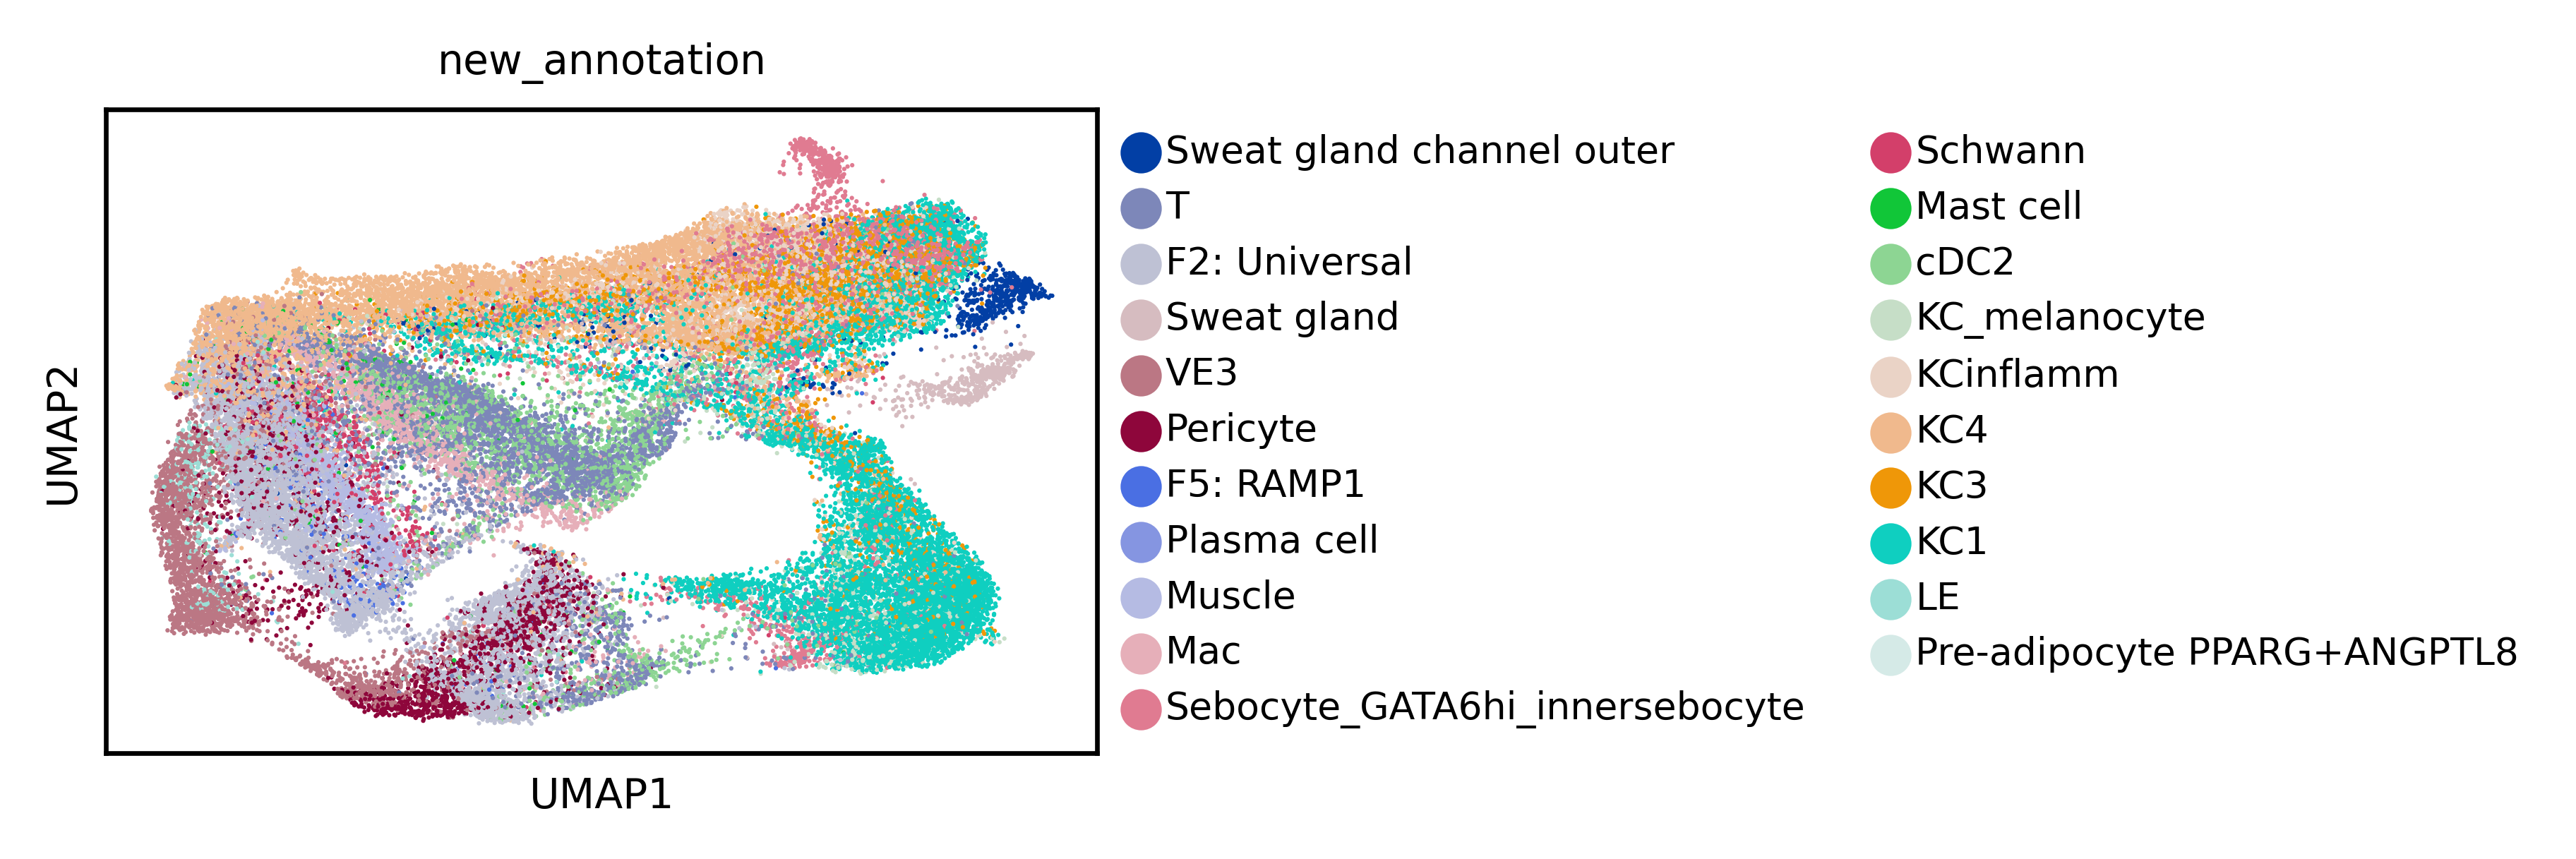

In [36]:
# Visualize UMAP
sc.pl.umap(adata, color=cell_type_key)

In [37]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/NicheJEPA/{dataset_name}_embedded_clustered_cell_type_{model_timestamp}.h5ad')

In [38]:
# Read AnnData
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/NicheJEPA/{dataset_name}_embedded_clustered_cell_type_{model_timestamp}.h5ad')

['4', '10', '5', '11', '2', '12', '9', '15', '1', '3', '13', '16', '7', '8', '6', '0', '18', '14', '17']
predicted_cell_type
0     6349
1     5051
2     4769
3     4615
4     4084
5     3826
6     3465
7     3415
8     3280
9     3271
10    2599
11    2343
12    2218
13    1252
14    1076
15     901
16     693
17     282
18     166
Name: count, dtype: int64
Optimal Mappings:
Sweat gland channel outer -> 6 (Overlap: 10)
T -> 5 (Overlap: 1693)
F2: Universal -> 2 (Overlap: 2696)
Sweat gland -> 14 (Overlap: 495)
VE3 -> 11 (Overlap: 1832)
Pericyte -> 10 (Overlap: 638)
F5: RAMP1 -> 13 (Overlap: 121)
Plasma cell -> 18 (Overlap: 0)
Muscle -> 16 (Overlap: 557)
Mac -> 4 (Overlap: 226)
Sebocyte_GATA6hi_innersebocyte -> 17 (Overlap: 281)
Mast cell -> 15 (Overlap: 2)
cDC2 -> 9 (Overlap: 1064)
KC_melanocyte -> 8 (Overlap: 172)
KCinflamm -> 0 (Overlap: 1367)
KC4 -> 3 (Overlap: 2269)
KC3 -> 7 (Overlap: 1379)
KC1 -> 1 (Overlap: 3981)
LE -> 12 (Overlap: 7)

Total Maximum Overlap: 18790


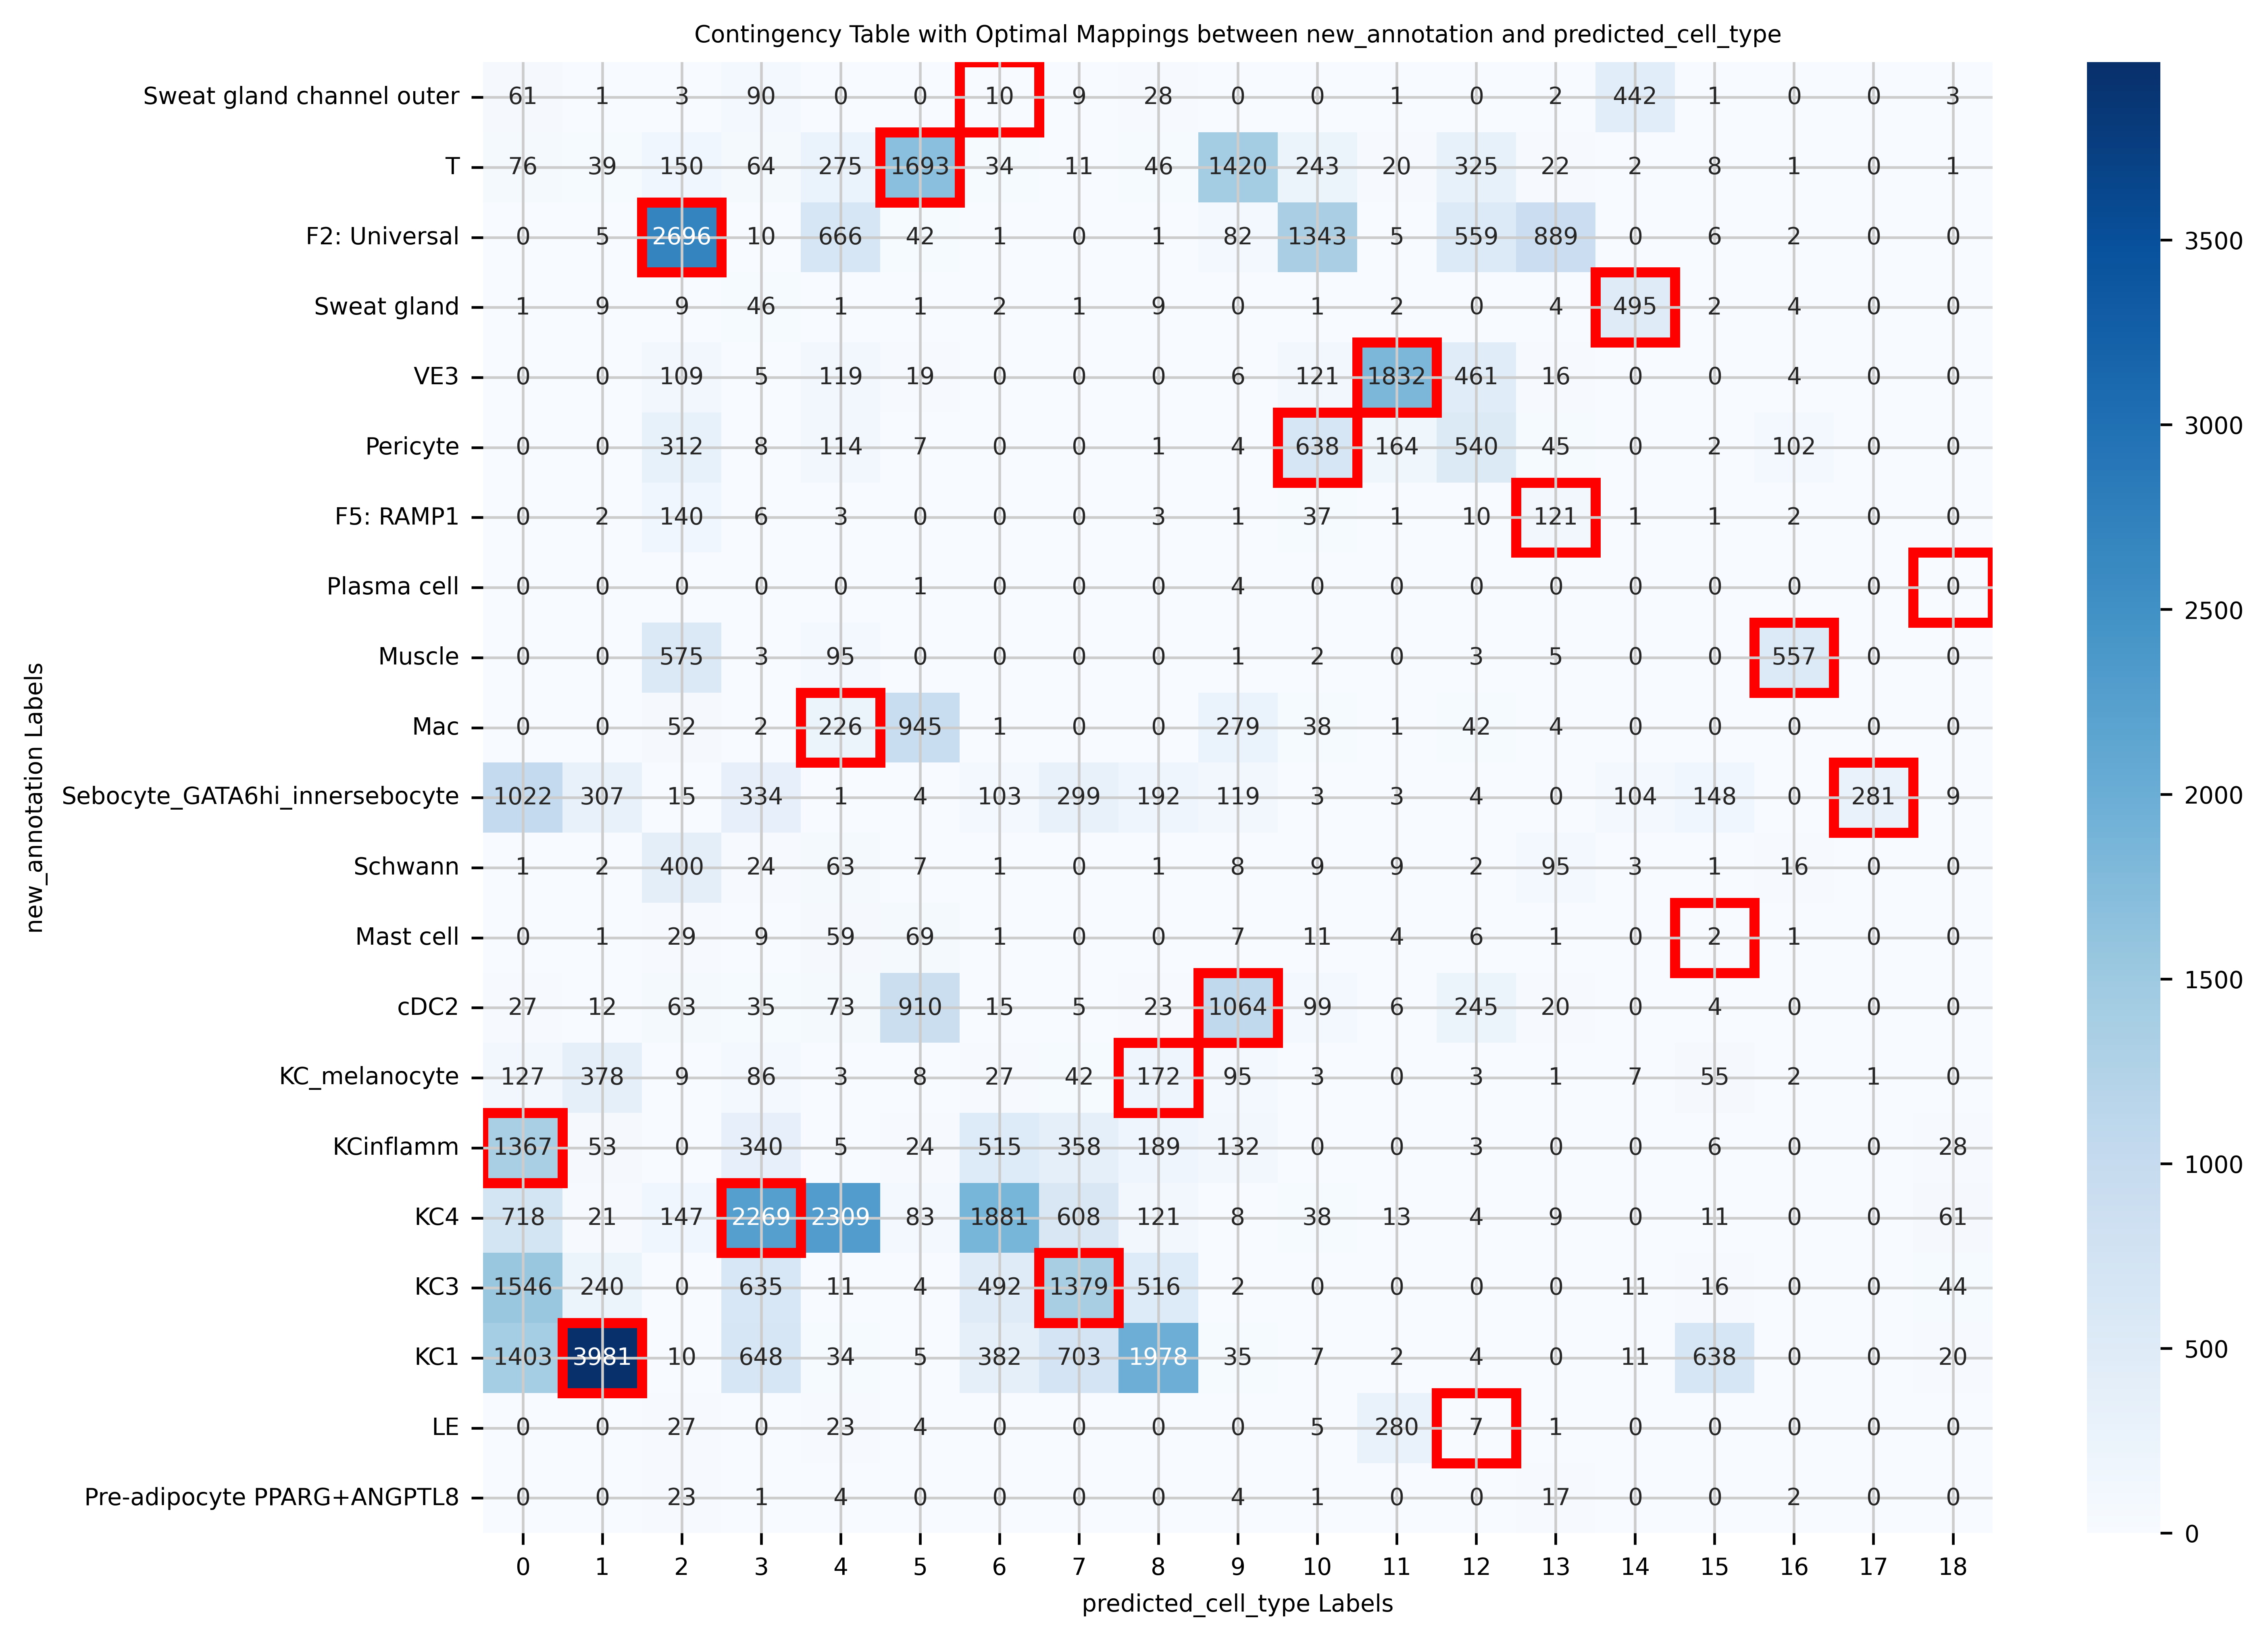

In [39]:
print(adata.obs[latent_cell_cluster_key].unique().tolist())
print(adata.obs[latent_cell_cluster_key].value_counts())
max_overlap_plot(adata.obs, cell_type_key, latent_cell_cluster_key)

In [ ]:
inferred_cell_types_ordered = [
    '14',
    '5',
    '2',
    '16',
    '12',
    '10',
    '6',
    '18',
    '13',
    '8',
    '7',
    '17',
    '15',
    '9',
    '4',
    '3',
    '11',
    '0',
    '1',
    '20',
    '19',]

In [ ]:
# Plot NicheJEPA cell type
label2celltype = {}
current_index = 0  # To keep track of the new indices

for cell_type in inferred_cell_types_ordered:
    if not isinstance(cell_type, str):
        if math.isnan(cell_type):
            continue # skip NaN values
    label2celltype[str(current_index)] = cell_type
    current_index += 1

pred_palette = {
    label2celltype.get(k, k): v
    for k, v in custom_palette.items()
}

batch_ids = adata.obs[batch_key].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs[batch_key] == batch_id]
    file_name = f'{dataset_name}_{batch_id}_nichejepa_cell_types_{model_timestamp}.svg'
    sc.pl.spatial(adata_batch,
                  color=latent_cell_cluster_key,
                  palette=pred_palette,
                  spot_size=spot_sizes[i],
                  save=file_name)

In [40]:
# Compute metrics
labels = adata.obs[cell_type_key]
labels_pred = adata.obs[latent_cell_cluster_key]
labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])

nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
ari_score = adjusted_rand_score(labels, labels_pred)

print(f"NMI scores: {nmi_score}.")
print(f"ARI scores: {ari_score}.")

NMI scores: 0.424400863522678.
ARI scores: 0.2241154467630181.


#### 3.1.4 Quantitative Performance

In [41]:
# Compute metrics over different resolutions
nmi_scores = []
ari_scores = []
n_cell_types_list = []

nmi_scores.append(nmi_score)
ari_scores.append(ari_score)
n_cell_types_list.append(adata.obs[latent_cell_cluster_key].nunique())

latent_leiden_resolution_list = [latent_leiden_resolution,
                                 latent_leiden_resolution-0.04,
                                 latent_leiden_resolution-0.03,
                                 latent_leiden_resolution-0.02,
                                 latent_leiden_resolution-0.01,
                                 latent_leiden_resolution+0.01,
                                 latent_leiden_resolution+0.02,
                                 latent_leiden_resolution+0.03,
                                 latent_leiden_resolution+0.04]

for i, latent_leiden_resolution in enumerate(latent_leiden_resolution_list[1:]):

    sc.tl.leiden(adata,
                 neighbors_key='cell',
                 key_added=latent_cell_cluster_key,
                 resolution=latent_leiden_resolution)

    n_cell_types_list.append(adata.obs[latent_cell_cluster_key].nunique())
    
    labels = adata.obs[cell_type_key]
    labels_pred = adata.obs[latent_cell_cluster_key]
    labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])
    
    nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
    ari_score = adjusted_rand_score(labels, labels_pred)

    nmi_scores.append(nmi_score)
    ari_scores.append(ari_score)

    # Store on disk
    metrics_df = pd.DataFrame({
        'leiden_resolution': latent_leiden_resolution_list[:i+2],
        'n_cell_types': n_cell_types_list,
        'NMI': nmi_scores,
        'ARI': ari_scores
    })
    metrics_df.to_csv(f'{benchmarking_artifacts_folder_path}/results/{dataset_name}_nichejepa_metric_scores_cell_type_{model_timestamp}.csv', index=False)

print(f"NMI scores: {nmi_scores}.")
print(f"ARI scores: {ari_scores}.")

NMI scores: [np.float64(0.424400863522678), np.float64(0.42537943262186206), np.float64(0.427012533711081), np.float64(0.43229988532541774), np.float64(0.4332516723932717), np.float64(0.4247958178584101), np.float64(0.4235995639020304), np.float64(0.42712860070434555), np.float64(0.42676453818500515)].
ARI scores: [0.2241154467630181, 0.22417907892223574, 0.22346495193752614, 0.22736385354201077, 0.22876329840168955, 0.22181493326323842, 0.21914933254708263, 0.2246967695477112, 0.22325813733234132].


### 3.2 chl59-8b_1p (NanoString CosMx Human NSCLC)

#### 3.2.1 Load Data

In [ ]:
# Define dataset params
dataset_name = 'chl59-8b_1p'
batches = ['Lung9_Rep1',
           'Lung9_Rep2',
           'Lung5_Rep1',
           'Lung5_Rep2',
           'Lung6',
           'Lung12']
cell_type_key = 'cell_type'
batch_key = 'batch'
spot_sizes = [80 * 0.18] * len(batches)

In [ ]:
# Load adata batches and concatenate for inference
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)

            # Filter cells without niche labels
            adata = adata[~adata.obs[cell_type_key].isna()]

            adata.obs[batch_key] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)
adata.obsm['spatial'] = adata.obsm['spatial'] * 0.18 # conversion rate from https://nanostring-public-share.s3.us-west-2.amazonaws.com/SMI-Compressed/SMI-ReadMe.html

In [ ]:
adata.obs[cell_type_key].value_counts()

#### 3.2.2 Load Embeddings

In [ ]:
# Load embeddings from 2.1
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/NicheJEPA/{dataset_name}_embedded_{model_timestamp}.h5ad')

In [ ]:
# Compute neighbors and UMAP 
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep=f'cell_emb',
                key_added='cell')
sc.tl.umap(adata,
           neighbors_key='cell')

In [ ]:
# Visualize UMAP
sc.pl.umap(adata, color=cell_type_key)

In [ ]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/NicheJEPA/{dataset_name}_embedded_cell_type_{model_timestamp}.h5ad')

In [ ]:
# Read AnnData
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/NicheJEPA/{dataset_name}_embedded_cell_type_{model_timestamp}.h5ad')

#### 3.2.3 Highlight Run (Matching Ground Truth Number of Niches)

In [ ]:
# Compute Leiden clustering (matching the number of clusters with the ground truth with > 100 cells -> 12)
latent_leiden_resolution = 0.45

sc.tl.leiden(adata,
             neighbors_key='cell',
             key_added=latent_cell_cluster_key,
             resolution=latent_leiden_resolution)

In [ ]:
adata.obs[latent_cell_cluster_key].value_counts()

In [ ]:
# Visualize UMAP
sc.pl.umap(adata, color=latent_cell_cluster_key)

In [ ]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/NicheJEPA/{dataset_name}_embedded_cell_type_clustered_{model_timestamp}.h5ad')

In [ ]:
# Read AnnData
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/NicheJEPA/{dataset_name}_embedded_clustered_cell_type_{model_timestamp}.h5ad')

In [ ]:
print(adata.obs[latent_cell_cluster_key].unique().tolist())
print(adata.obs[latent_cell_cluster_key].value_counts())
max_overlap_plot(adata.obs, cell_type_key, latent_cell_cluster_key)

In [ ]:
inferred_cell_types_ordered = [
    '3',
    '2',
    '7',
    '8',
    '4',
    '9',
    '6',
    '1',
    '5',
    '0']

In [ ]:
# Plot NicheJEPA cell types
label2celltype = {}
current_index = 0  # To keep track of the new indices

for cell_type in inferred_cell_types_ordered:
    if not isinstance(cell_type, str):
        if math.isnan(cell_type):
            continue # skip NaN values
    label2celltype[str(current_index)] = cell_type
    current_index += 1

pred_palette = {
    label2celltype.get(k, k): v
    for k, v in custom_palette.items()
}

batch_ids = adata.obs[batch_key].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs[batch_key] == batch_id]
    file_name = f'{dataset_name}_{batch_id}_nichejepa_cell_types_{model_timestamp}.svg'
    sc.pl.spatial(adata_batch,
                  color=latent_cell_cluster_key,
                  palette=pred_palette,
                  spot_size=spot_sizes[i],
                  save=file_name)

In [ ]:
# Compute metrics
labels = adata.obs[cell_type_key]
labels_pred = adata.obs[latent_cell_cluster_key]
labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])

nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
ari_score = adjusted_rand_score(labels, labels_pred)

print(f"NMI scores: {nmi_score}.")
print(f"ARI scores: {ari_score}.")

#### 3.2.4 Quantitative Performance

In [ ]:
# Compute metrics over different resolutions
nmi_scores = []
ari_scores = []
n_cell_types_list = []

nmi_scores.append(nmi_score)
ari_scores.append(ari_score)
n_cell_types_list.append(adata.obs[latent_cell_cluster_key].nunique())

latent_leiden_resolution_list = [latent_leiden_resolution,
                                 latent_leiden_resolution-0.04,
                                 latent_leiden_resolution-0.03,
                                 latent_leiden_resolution-0.02,
                                 latent_leiden_resolution-0.01,
                                 latent_leiden_resolution+0.01,
                                 latent_leiden_resolution+0.02,
                                 latent_leiden_resolution+0.03,
                                 latent_leiden_resolution+0.04]

for i, latent_leiden_resolution in enumerate(latent_leiden_resolution_list[1:]):

    sc.tl.leiden(adata,
                 neighbors_key='cell',
                 key_added=latent_cell_cluster_key,
                 resolution=latent_leiden_resolution)

    n_cell_types_list.append(adata.obs[latent_cell_cluster_key].nunique())
    
    labels = adata.obs[cell_type_key]
    labels_pred = adata.obs[latent_cell_cluster_key]
    labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])
    
    nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
    ari_score = adjusted_rand_score(labels, labels_pred)

    nmi_scores.append(nmi_score)
    ari_scores.append(ari_score)

    # Store on disk
    metrics_df = pd.DataFrame({
        'leiden_resolution': latent_leiden_resolution_list[:i+2],
        'n_cell_types': n_cell_types_list,
        'NMI': nmi_scores,
        'ARI': ari_scores
    })
    metrics_df.to_csv(f'{benchmarking_artifacts_folder_path}/results/{dataset_name}_nichejepa_metric_scores_cell_type_{model_timestamp}.csv', index=False)

print(f"NMI scores: {nmi_scores}.")
print(f"ARI scores: {ari_scores}.")

### 3.3 xhk1007-CV1-41b_1p (Xenium Human Renal Cell Carcinoma)

#### 3.3.1 Load Data

In [ ]:
# Define dataset params
dataset_name = 'xhk1007-CV1-41b_1p'
batches = ['CV1-KID-0-FT-3', # 'batch1',
           'CV1-KID-0-FT-1' # 'batch14'
          ]
cell_type_key = 'level_3_cell_type'
batch_key = 'batch'
spot_sizes = [30] * len(batches)

In [ ]:
# Load adata batches and concatenate for inference
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)

            # Filter cells without cell type labels
            adata = adata[~adata.obs[cell_type_key].isna()]

            adata.obs[batch_key] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)

In [ ]:
print(adata.obs[cell_type_key].value_counts())

#### 3.3.2 Retrieve Embeddings

In [ ]:
# Generate zero-shot embeddings for cells
adata = harmonize_tokenize_embed_pipeline(
    adata=adata,
    sample_key=batch_key,
    model_folder_path=model_folder_path,
    cache_directory_path=cache_directory_path,
    min_cells_per_gene=min_cells_per_gene,
    batch_size=128)

In [ ]:
# Compute neighbors and UMAP 
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep=f'cell_emb',
                key_added='cell')
sc.tl.umap(adata,
           neighbors_key='cell')

In [ ]:
# Visualize UMAP
sc.pl.umap(adata, color=cell_type_key)

In [ ]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/NicheJEPA/{dataset_name}_embedded_{model_timestamp}.h5ad')

In [ ]:
# Read AnnData
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/NicheJEPA/{dataset_name}_embedded_{model_timestamp}.h5ad')

#### 3.3.3 Highlight Run (Matching Ground Truth Number of Niches)

In [ ]:
# Compute Leiden clustering (matching the number of clusters with the ground truth with > 100 cells -> 13)
latent_leiden_resolution = 0.55

sc.tl.leiden(adata,
             neighbors_key='cell',
             key_added=latent_cell_cluster_key,
             resolution=latent_leiden_resolution)

In [ ]:
adata.obs[latent_cell_cluster_key].value_counts()

In [ ]:
# Visualize UMAP
sc.pl.umap(adata, color=cell_type_key)

In [ ]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/NicheJEPA/{dataset_name}_embedded_clustered_cell_type_{model_timestamp}.h5ad')

In [ ]:
# Read AnnData
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/NicheJEPA/{dataset_name}_embedded_clustered_cell_type_{model_timestamp}.h5ad')

In [ ]:
print(adata.obs[latent_cell_cluster_key].unique().tolist())
print(adata.obs[latent_cell_cluster_key].value_counts())
max_overlap_plot(adata.obs, cell_type_key, latent_cell_cluster_key)

In [ ]:
inferred_cell_types_ordered = [
    '9',
    '11',
    '8',
    '7',
    '5',
    '1',
    '10',
    '12',
    '6',
    '3',
    '4',
    '2',
    '0']

In [ ]:
# Plot NicheJEPA cell type
label2celltype = {}
current_index = 0  # To keep track of the new indices

for cell_type in inferred_cell_types_ordered:
    if not isinstance(cell_type, str):
        if math.isnan(cell_type):
            continue # skip NaN values
    label2celltype[str(current_index)] = cell_type
    current_index += 1

pred_palette = {
    label2celltype.get(k, k): v
    for k, v in custom_palette.items()
}

batch_ids = adata.obs[batch_key].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs[batch_key] == batch_id]
    file_name = f'{dataset_name}_{batch_id}_nichejepa_cell_types_{model_timestamp}.svg'
    sc.pl.spatial(adata_batch,
                  color=latent_cell_cluster_key,
                  palette=pred_palette,
                  spot_size=spot_sizes[i],
                  save=file_name)

In [ ]:
# Compute metrics
labels = adata.obs[cell_type_key]
labels_pred = adata.obs[latent_cell_cluster_key]
labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])

nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
ari_score = adjusted_rand_score(labels, labels_pred)

print(f"NMI scores: {nmi_score}.")
print(f"ARI scores: {ari_score}.")

#### 3.3.4 Quantitative Performance

In [ ]:
# Compute metrics over different resolutions
nmi_scores = []
ari_scores = []
n_cell_types_list = []

nmi_scores.append(nmi_score)
ari_scores.append(ari_score)
n_cell_types_list.append(adata.obs[latent_cell_cluster_key].nunique())

latent_leiden_resolution_list = [latent_leiden_resolution,
                                 latent_leiden_resolution-0.04,
                                 latent_leiden_resolution-0.03,
                                 latent_leiden_resolution-0.02,
                                 latent_leiden_resolution-0.01,
                                 latent_leiden_resolution+0.01,
                                 latent_leiden_resolution+0.02,
                                 latent_leiden_resolution+0.03,
                                 latent_leiden_resolution+0.04]

for i, latent_leiden_resolution in enumerate(latent_leiden_resolution_list[1:]):

    sc.tl.leiden(adata,
                 neighbors_key='cell',
                 key_added=latent_cell_cluster_key,
                 resolution=latent_leiden_resolution)

    n_cell_types_list.append(adata.obs[latent_cell_cluster_key].nunique())
    
    labels = adata.obs[cell_type_key]
    labels_pred = adata.obs[latent_cell_cluster_key]
    labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])
    
    nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
    ari_score = adjusted_rand_score(labels, labels_pred)

    nmi_scores.append(nmi_score)
    ari_scores.append(ari_score)

    # Store on disk
    metrics_df = pd.DataFrame({
        'leiden_resolution': latent_leiden_resolution_list[:i+2],
        'n_cell_types': n_cell_types_list,
        'NMI': nmi_scores,
        'ARI': ari_scores
    })
    metrics_df.to_csv(f'{benchmarking_artifacts_folder_path}/results/{dataset_name}_nichejepa_metric_scores_cell_type_{model_timestamp}.csv', index=False)

print(f"NMI scores: {nmi_scores}.")
print(f"ARI scores: {ari_scores}.")

### 3.4 shp75-4b_1p (STARmap Human Placenta)

#### 3.4.1 Load Data

In [ ]:
# Define dataset params
dataset_name = 'shp75-4b_1p'
batches = ['STARmap-ISS_sample_W11_',
           'STARmap-ISS_sample_W7_',
           'STARmap-ISS_sample_W8-2_',
           'STARmap-ISS_sample_W9_',
          ]
cell_type_key = 'leiden'
batch_key = 'batch'
spot_sizes = [30] * len(batches)

In [ ]:
# Load adata batches and concatenate for inference
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)

            # Filter cells without cell type labels
            adata = adata[~adata.obs[cell_type_key].isna()]

            adata.obs[batch_key] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)

In [ ]:
print(adata.obs[cell_type_key].value_counts())

#### 3.4.2 Retrieve Embeddings

In [ ]:
# Generate zero-shot embeddings for cells
adata = harmonize_tokenize_embed_pipeline(
    adata=adata,
    sample_key=batch_key,
    model_folder_path=model_folder_path,
    cache_directory_path=cache_directory_path,
    min_cells_per_gene=min_cells_per_gene,
    batch_size=128)

In [ ]:
# Compute neighbors and UMAP 
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep=f'cell_emb',
                key_added='cell')
sc.tl.umap(adata,
           neighbors_key='cell')

In [ ]:
# Visualize UMAP
sc.pl.umap(adata, color=cell_type_key)

In [ ]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/NicheJEPA/{dataset_name}_embedded_cell_type_{model_timestamp}.h5ad')

In [ ]:
# Read AnnData
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/NicheJEPA/{dataset_name}_embedded_cell_type_{model_timestamp}.h5ad')

#### 3.4.3 Highlight Run (Matching Ground Truth Number of Niches)

In [ ]:
# Compute Leiden clustering (matching the number of clusters with the ground truth with > 100 cells -> 13)
latent_leiden_resolution = 0.9

sc.tl.leiden(adata,
             neighbors_key='cell',
             key_added=latent_cell_cluster_key,
             resolution=latent_leiden_resolution)

In [ ]:
adata.obs[latent_cell_cluster_key].value_counts()

In [ ]:
# Visualize UMAP
sc.pl.umap(adata, color=cell_type_key)

In [ ]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/NicheJEPA/{dataset_name}_embedded_clustered_cell_type_{model_timestamp}.h5ad')

In [ ]:
# Read AnnData
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/NicheJEPA/{dataset_name}_embedded_clustered_cell_type_{model_timestamp}.h5ad')

In [ ]:
print(adata.obs[latent_cell_cluster_key].unique().tolist())
print(adata.obs[latent_cell_cluster_key].value_counts())
max_overlap_plot(adata.obs, cell_type_key, latent_cell_cluster_key)

In [ ]:
inferred_cell_types_ordered = [
    '7',
    '2',
    '6',
    '4',
    '1',
    '5',
    '10',
    '9',
    '0',
    '12',
    '8',
    '3',
    '11',]

In [ ]:
# Plot NicheJEPA cell type
label2celltype = {}
current_index = 0  # To keep track of the new indices

for cell_type in inferred_cell_types_ordered:
    if not isinstance(cell_type, str):
        if math.isnan(cell_type):
            continue # skip NaN values
    label2celltype[str(current_index)] = cell_type
    current_index += 1

pred_palette = {
    label2celltype.get(k, k): v
    for k, v in custom_palette.items()
}

batch_ids = adata.obs[batch_key].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs[batch_key] == batch_id]
    file_name = f'{dataset_name}_{batch_id}_nichejepa_cell_types_{model_timestamp}.svg'
    sc.pl.spatial(adata_batch,
                  color=latent_cell_cluster_key,
                  palette=pred_palette,
                  spot_size=spot_sizes[i],
                  save=file_name)

In [ ]:
# Compute metrics
labels = adata.obs[cell_type_key]
labels_pred = adata.obs[latent_cell_cluster_key]
labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])

nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
ari_score = adjusted_rand_score(labels, labels_pred)

print(f"NMI scores: {nmi_score}.")
print(f"ARI scores: {ari_score}.")

#### 3.4.4 Quantitative Performance

In [ ]:
# Compute metrics over different resolutions
nmi_scores = []
ari_scores = []
n_cell_types_list = []

nmi_scores.append(nmi_score)
ari_scores.append(ari_score)
n_cell_types_list.append(adata.obs[latent_cell_cluster_key].nunique())

latent_leiden_resolution_list = [latent_leiden_resolution,
                                 latent_leiden_resolution-0.04,
                                 latent_leiden_resolution-0.03,
                                 latent_leiden_resolution-0.02,
                                 latent_leiden_resolution-0.01,
                                 latent_leiden_resolution+0.01,
                                 latent_leiden_resolution+0.02,
                                 latent_leiden_resolution+0.03,
                                 latent_leiden_resolution+0.04]

for i, latent_leiden_resolution in enumerate(latent_leiden_resolution_list[1:]):

    sc.tl.leiden(adata,
                 neighbors_key='cell',
                 key_added=latent_cell_cluster_key,
                 resolution=latent_leiden_resolution)

    n_cell_types_list.append(adata.obs[latent_cell_cluster_key].nunique())
    
    labels = adata.obs[cell_type_key]
    labels_pred = adata.obs[latent_cell_cluster_key]
    labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])
    
    nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
    ari_score = adjusted_rand_score(labels, labels_pred)

    nmi_scores.append(nmi_score)
    ari_scores.append(ari_score)

    # Store on disk
    metrics_df = pd.DataFrame({
        'leiden_resolution': latent_leiden_resolution_list[:i+2],
        'n_cell_types': n_cell_types_list,
        'NMI': nmi_scores,
        'ARI': ari_scores
    })
    metrics_df.to_csv(f'{benchmarking_artifacts_folder_path}/results/{dataset_name}_nichejepa_metric_scores_cell_type_{model_timestamp}.csv', index=False)

print(f"NMI scores: {nmi_scores}.")
print(f"ARI scores: {ari_scores}.")

### 3.5 xhp1016-18b_1p (Xenium Human Pancreas)

#### 3.5.1 Load Data

In [ ]:
# Define dataset params
dataset_name = 'xhp1016-18b_1p'
batches = ['output-XETG00055__0073068__Hml4-PNC-0-FFPE-1-s4__20250814__132610', # batch3
           'output-XETG00055__0073075__Hml7-PNC-0-FFPE-1-s4__20250814__132610', # batch12
          ]
cell_type_key = 'Annotation_high'
batch_key = 'batch'
spot_sizes = [30] * len(batches)

In [ ]:
# Load adata batches and concatenate for inference
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)

            # Filter cells without cell type labels
            adata = adata[~adata.obs[cell_type_key].isna()]

            adata.obs[batch_key] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)

In [ ]:
print(adata.obs[cell_type_key].value_counts())

#### 3.5.2 Retrieve Embeddings

In [ ]:
# Generate zero-shot embeddings for cells
adata = harmonize_tokenize_embed_pipeline(
    adata=adata,
    sample_key=None,
    model_folder_path=model_folder_path,
    cache_directory_path=cache_directory_path,
    min_cells_per_gene=min_cells_per_gene,
    batch_size=128)

In [ ]:
# Compute neighbors and UMAP 
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep=f'cell_emb',
                key_added='cell')
sc.tl.umap(adata,
           neighbors_key='cell')

In [ ]:
# Visualize UMAP
sc.pl.umap(adata, color=cell_type_key)

In [ ]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/NicheJEPA/{dataset_name}_embedded_cell_type_{model_timestamp}.h5ad')

In [ ]:
# Read AnnData
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/NicheJEPA/{dataset_name}_embedded_cell_type_{model_timestamp}.h5ad')

#### 3.5.3 Highlight Run (Matching Ground Truth Number of Niches)

In [ ]:
# Compute Leiden clustering (matching the number of clusters with the ground truth with > 100 cells -> 16)
latent_leiden_resolution = 0.7

sc.tl.leiden(adata,
             neighbors_key='cell',
             key_added=latent_cell_cluster_key,
             resolution=latent_leiden_resolution)

In [ ]:
adata.obs[latent_cell_cluster_key].value_counts()

In [ ]:
# Visualize UMAP
sc.pl.umap(adata, color=cell_type_key)

In [ ]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/NicheJEPA/{dataset_name}_embedded_clustered_cell_type_{model_timestamp}.h5ad')

In [ ]:
# Read AnnData
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/NicheJEPA/{dataset_name}_embedded_clustered_cell_type_{model_timestamp}.h5ad')

In [ ]:
print(adata.obs[latent_cell_cluster_key].unique().tolist())
print(adata.obs[latent_cell_cluster_key].value_counts())
max_overlap_plot(adata.obs, cell_type_key, latent_cell_cluster_key)

In [ ]:
inferred_cell_types_ordered = [
    '6',
    '3',
    '15',
    '1',
    '4',
    '5',
    '12',
    '9',
    '8',
    '13',
    '10',
    '7',
    '0',
    '14',
    '11',
    '2',]

In [ ]:
# Plot NicheJEPA cell type
label2celltype = {}
current_index = 0  # To keep track of the new indices

for cell_type in inferred_cell_types_ordered:
    if not isinstance(cell_type, str):
        if math.isnan(cell_type):
            continue # skip NaN values
    label2celltype[str(current_index)] = cell_type
    current_index += 1

pred_palette = {
    label2celltype.get(k, k): v
    for k, v in custom_palette.items()
}

batch_ids = adata.obs[batch_key].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs[batch_key] == batch_id]
    file_name = f'{dataset_name}_{batch_id}_nichejepa_cell_types_{model_timestamp}.svg'
    sc.pl.spatial(adata_batch,
                  color=latent_cell_cluster_key,
                  palette=pred_palette,
                  spot_size=spot_sizes[i],
                  save=file_name)

In [ ]:
# Compute metrics
labels = adata.obs[cell_type_key]
labels_pred = adata.obs[latent_cell_cluster_key]
labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])

nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
ari_score = adjusted_rand_score(labels, labels_pred)

print(f"NMI scores: {nmi_score}.")
print(f"ARI scores: {ari_score}.")

#### 3.5.4 Quantitative Performance

In [ ]:
# Compute metrics over different resolutions
nmi_scores = []
ari_scores = []
n_cell_types_list = []

nmi_scores.append(nmi_score)
ari_scores.append(ari_score)
n_cell_types_list.append(adata.obs[latent_cell_cluster_key].nunique())

latent_leiden_resolution_list = [latent_leiden_resolution,
                                 latent_leiden_resolution-0.04,
                                 latent_leiden_resolution-0.03,
                                 latent_leiden_resolution-0.02,
                                 latent_leiden_resolution-0.01,
                                 latent_leiden_resolution+0.01,
                                 latent_leiden_resolution+0.02,
                                 latent_leiden_resolution+0.03,
                                 latent_leiden_resolution+0.04]

for i, latent_leiden_resolution in enumerate(latent_leiden_resolution_list[1:]):

    sc.tl.leiden(adata,
                 neighbors_key='cell',
                 key_added=latent_cell_cluster_key,
                 resolution=latent_leiden_resolution)

    n_cell_types_list.append(adata.obs[latent_cell_cluster_key].nunique())
    
    labels = adata.obs[cell_type_key]
    labels_pred = adata.obs[latent_cell_cluster_key]
    labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])
    
    nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
    ari_score = adjusted_rand_score(labels, labels_pred)

    nmi_scores.append(nmi_score)
    ari_scores.append(ari_score)

    # Store on disk
    metrics_df = pd.DataFrame({
        'leiden_resolution': latent_leiden_resolution_list[:i+2],
        'n_cell_types': n_cell_types_list,
        'NMI': nmi_scores,
        'ARI': ari_scores
    })
    metrics_df.to_csv(f'{benchmarking_artifacts_folder_path}/results/{dataset_name}_nichejepa_metric_scores_cell_type_{model_timestamp}.csv', index=False)

print(f"NMI scores: {nmi_scores}.")
print(f"ARI scores: {ari_scores}.")

### 3.6 shk2005-1b_1p (SlideSeqV2 Human Kidney)

#### 3.6.1 Load Data

In [ ]:
# Define dataset params
dataset_name = 'shk2005-1b_1p'
cell_type_key = 'cell_type'
spot_size = 30

In [ ]:
adata = sc.read_h5ad(f'{st_data_silver_folder_path}/{dataset_name}/Puck_200104_15_with_emb_NEMO_commongenes.h5ad')

# Filter cells without niche labels
adata = adata[~adata.obs[cell_type_key].isna()]

In [ ]:
adata.obs[cell_type_key].value_counts()

#### 3.6.2 Retrieve Embeddings

In [ ]:
# Generate zero-shot embeddings for cells
adata = harmonize_tokenize_embed_pipeline(
    adata=adata,
    sample_key=None,
    model_folder_path=model_folder_path,
    cache_directory_path=cache_directory_path,
    min_cells_per_gene=min_cells_per_gene,
    batch_size=128)

In [ ]:
# Compute neighbors and UMAP 
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep=f'cell_emb',
                key_added='cell')
sc.tl.umap(adata,
           neighbors_key='cell')

In [ ]:
# Visualize UMAP
sc.pl.umap(adata, color=cell_type_key)

In [ ]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/NicheJEPA/{dataset_name}_embedded_cell_type_{model_timestamp}.h5ad')

In [ ]:
# Read AnnData
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/NicheJEPA/{dataset_name}_embedded_cell_type_{model_timestamp}.h5ad')

#### 3.6.3 Highlight Run (Matching Ground Truth Number of Niches)

In [ ]:
# Compute Leiden clustering (matching the number of clusters with the ground truth with > 100 cells -> 12)
latent_leiden_resolution = 0.85

sc.tl.leiden(adata,
             neighbors_key='cell',
             key_added=latent_cell_cluster_key,
             resolution=latent_leiden_resolution)

In [ ]:
adata.obs[latent_cell_cluster_key].value_counts()

In [ ]:
# Visualize UMAP
sc.pl.umap(adata, color=latent_cell_cluster_key)

In [ ]:
# Save updated AnnData
try:
    del(adata.uns['spatial'])
except:
    pass
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/NicheJEPA/{dataset_name}_embedded_clustered_cell_type_{model_timestamp}.h5ad')

In [ ]:
# Read AnnData
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/NicheJEPA/{dataset_name}_embedded_clustered_cell_type_{model_timestamp}.h5ad')

In [ ]:
print(adata.obs[latent_cell_cluster_key].unique().tolist())
print(adata.obs[latent_cell_cluster_key].value_counts())
max_overlap_plot(adata.obs, cell_type_key, latent_cell_cluster_key)

In [ ]:
inferred_cell_types_ordered = [
    '0',
    '11',
    '10',
    '4',
    '2',
    '6',
    '1',
    '7',
    '8',
    '9',
    '5',
    '3',]

In [ ]:
# Plot NicheJEPA cell types
label2celltype = {}
current_index = 0  # To keep track of the new indices

for cell_type in inferred_cell_types_ordered:
    if not isinstance(cell_type, str):
        if math.isnan(cell_type):
            continue # skip NaN values
    label2celltype[str(current_index)] = cell_type
    current_index += 1

pred_palette = {
    label2celltype.get(k, k): v
    for k, v in custom_palette.items()
}

file_name = f'{dataset_name}_nichejepa_cell_types_{model_timestamp}.svg'
sc.pl.spatial(adata,
              color=latent_cell_cluster_key,
              palette=pred_palette,
              spot_size=spot_size,
              save=file_name)

In [ ]:
# Plot NicheJEPA cell types
label2celltype = {}
current_index = 0  # To keep track of the new indices

for cell_type in inferred_cell_types_ordered:
    if not isinstance(cell_type, str):
        if math.isnan(cell_type):
            continue # skip NaN values
    label2celltype[str(current_index)] = cell_type
    current_index += 1

pred_palette = {
    label2celltype.get(k, k): v
    for k, v in custom_palette.items()
}

file_name = f'{dataset_name}_nichejepa_cell_types_{model_timestamp}.svg'
sc.pl.spatial(adata,
              color=latent_cell_cluster_key,
              palette=pred_palette,
              spot_size=spot_size,
              save=file_name)

In [ ]:
# Compute metrics
labels = adata.obs[cell_type_key]
labels_pred = adata.obs[latent_cell_cluster_key]
labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])

nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
ari_score = adjusted_rand_score(labels, labels_pred)

print(f"NMI scores: {nmi_score}.")
print(f"ARI scores: {ari_score}.")

#### 3.6.4 Quantitative Performance

In [ ]:
# Compute metrics over different resolutions
nmi_scores = []
ari_scores = []
n_cell_types_list = []

nmi_scores.append(nmi_score)
ari_scores.append(ari_score)
n_cell_types_list.append(adata.obs[latent_cell_cluster_key].nunique())

latent_leiden_resolution_list = [latent_leiden_resolution,
                                 latent_leiden_resolution-0.04,
                                 latent_leiden_resolution-0.03,
                                 latent_leiden_resolution-0.02,
                                 latent_leiden_resolution-0.01,
                                 latent_leiden_resolution+0.01,
                                 latent_leiden_resolution+0.02,
                                 latent_leiden_resolution+0.03,
                                 latent_leiden_resolution+0.04]

for i, latent_leiden_resolution in enumerate(latent_leiden_resolution_list[1:]):

    sc.tl.leiden(adata,
                  neighbors_key='cell',
                  key_added=latent_cell_cluster_key,
                  resolution=latent_leiden_resolution)

    n_cell_types_list.append(adata.obs[latent_cell_cluster_key].nunique())
    
    labels = adata.obs[cell_type_key]
    labels_pred = adata.obs[latent_cell_cluster_key]
    labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])
    
    nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
    ari_score = adjusted_rand_score(labels, labels_pred)

    nmi_scores.append(nmi_score)
    ari_scores.append(ari_score)

    # Store on disk
    metrics_df = pd.DataFrame({
        'leiden_resolution': latent_leiden_resolution_list[:i+2],
        'n_cell_types': n_cell_types_list,
        'NMI': nmi_scores,
        'ARI': ari_scores
    })
    metrics_df.to_csv(f'{benchmarking_artifacts_folder_path}/results/{dataset_name}_nichejepa_metric_scores_cell_type_{model_timestamp}.csv', index=False)

print(f"NMI scores: {nmi_scores}.")
print(f"ARI scores: {ari_scores}.")